# ZollerQu: long/short stock split (Qollab × IonQ hackathon)

This effort is supported by Qollab & IonQ.

Working notebook, built cell by cell. Local development only: the Qollab entry point will be a separate `main.py`, and the reusable code lives in the `stocks/` package next to this notebook.

## Run settings (change here, then Run All)

Two benchmark sizes. Each asset is one qubit.
- **Small**: the quick run. It finishes fast on any free Qollab simulator and is what judges will press Run on.
- **Large**: the full run on IonQ Forte 1 (noise model), up to its 29-qubit limit. It is slow in the shared queue, so we record the result and ship it.

`RUN_SIZES` lists the sizes the benchmark cells will run (later tasks). Add 16, 20 or 24 for a scaling table.
Above about 22 qubits two parts change: the exact optimum becomes the *best known* answer from classical solvers, and a noiseless simulation on a laptop is no longer possible (2^29 amplitudes). The IonQ run itself works up to 29.

`TRAIN_FRACTION`: chronological split of the weekly returns (first 70 % train, last 30 % test). `RISK_RETURN_WEIGHT` (eta): weight of expected return against risk in the score; 1.0 is a provisional default, not tuned.

`ETA_GRID`, `KEEP_FRACTION`, `TARGET_BUYS` (Task 3): the dial values that are all run, the share of links kept for each size (by strength of correlation), and how many assets to buy when the balance switch is on in 'buy or skip' mode.

In [1]:
import matplotlib
matplotlib.rcParams["figure.dpi"] = 70  # smaller chart images keep this notebook under 2 MB

QUBITS_SMALL = 12          # quick run (Qollab live demo)
QUBITS_LARGE = 29          # full run (IonQ Forte 1 noise model, maximum 29)
RUN_SIZES = [QUBITS_SMALL, QUBITS_LARGE]
TRAIN_FRACTION = 0.70      # first 70 % of weekly returns = training, last 30 % = test
RISK_RETURN_WEIGHT = 1.0   # eta in J = risk - eta * return; provisional, not tuned
ETA_GRID = (0.25, 0.5, 1.0, 2.0)   # Task 3: every dial value is run and reported (none is chosen on test data)
KEEP_FRACTION = {12: 1.0, 29: 0.60}  # share of links kept per size, ranked by |correlation|
TARGET_BUYS = None         # 'buy or skip' with balance on: how many assets to buy; None = half (n // 2)

for n in RUN_SIZES:
    if not 2 <= n <= 29:
        raise ValueError(f"size {n}: must be between 2 and 29 qubits (IonQ Forte 1 limit)")
print("benchmark sizes (qubits = assets):", RUN_SIZES)
print("train fraction:", TRAIN_FRACTION, "| risk-return weight eta (provisional):", RISK_RETURN_WEIGHT)
print("eta grid:", ETA_GRID, "| links kept per size:", KEEP_FRACTION, "| target buys:", TARGET_BUYS or "n // 2")

benchmark sizes (qubits = assets): [12, 29]
train fraction: 0.7 | risk-return weight eta (provisional): 1.0
eta grid: (0.25, 0.5, 1.0, 2.0) | links kept per size: {12: 1.0, 29: 0.6} | target buys: n // 2


## Task 1: Load and validate the OR-Library dataset

Source: J E Beasley, OR-Library, `indtrack1.txt` (index tracking problem 1, MIT licence). Downloaded once during development; nothing is downloaded at run time.

In [2]:
import hashlib
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "stocks").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from stocks import data, validate_data

print("repo root:", ROOT)

repo root: /Users/t/zollerqu-qollab


### 1.1 Source file as downloaded

In [3]:
raw = data.RAW_PATH
lines = raw.read_text().splitlines()
print("file:  ", raw.relative_to(ROOT), f"({raw.stat().st_size} bytes)")
print("sha256:", hashlib.sha256(raw.read_bytes()).hexdigest())
print("line 1:", repr(lines[0]))
print("line 2:", repr(lines[1]))
values_per_line = [len(line.split()) for line in lines[1:]]
print("lines after header:", len(values_per_line),
      "| with 4 values:", values_per_line.count(4),
      "| with 3 values:", values_per_line.count(3),
      "| total values:", sum(values_per_line))

file:   data/raw/indtrack1.txt (116665 bytes)
sha256: 258b917e304e21c87ae481b9baba0aefe877b657fa63483255c23162a74aa629
line 1: ' 31 290 '
line 2: ' 8749.31759356 8713.53262793 9001.60515134 8903.30299873 '
lines after header: 2336 | with 4 values: 2304 | with 3 values: 32 | total values: 9312


### 1.2 Parse and validate

`parse_orlib` accepts a layout only if the price count matches it **and** every series starts on a new line. It also checks that the first index price is near 8749 and that all prices are finite and positive. Any problem raises `DataFormatError`; nothing is dropped or filled in.

In [4]:
market, report = data.parse_orlib(raw)
print(report)
print("index:", market.index.shape, "| stocks:", market.prices.shape, "| names:", market.names[0], "...", market.names[-1])
print("first index price:", float(market.index[0]))
print(f"index range {market.index.min():.2f} .. {market.index.max():.2f} | "
      f"stock range {market.prices.min():.4f} .. {market.prices.max():.4f}")

ParseReport(header=(31, 290), n_values=9312, layout='(N+1)*(T+1)', n_series=32, observations=291)
index: (291,) | stocks: (291, 31) | names: s01 ... s31
first index price: 8749.31759356
index range 8713.53 .. 29550.18 | stock range 1.7928 .. 484.5881


### 1.3 Normalised CSV `data/hangseng_weekly.csv`

One row per observation: `week,index,s01,...,s31`. The source has no dates, so `week` is the observation number 0..290 in source order.

In [5]:
data.write_csv(market, data.CSV_PATH)
reloaded = data.load_csv(data.CSV_PATH)
same = (reloaded.names == market.names
        and (reloaded.index == market.index).all()
        and (reloaded.prices == market.prices).all())
print("reloaded identical to the parsed source:", same)
for line in data.CSV_PATH.read_text().splitlines()[:3]:
    print(line[:100] + " ...")

reloaded identical to the parsed source: True
week,index,s01,s02,s03,s04,s05,s06,s07,s08,s09,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21,s22,s ...
0,8749.31759356,9.33675195,14.37788798,7.36644878,29.46579511,5.55589992,8.55573087,16.41919306,9.95 ...
1,8713.53262793,9.86926631,14.18263271,7.40194974,27.33573763,5.44939705,8.50247943,16.41919306,9.28 ...


### 1.4 Licence notice

In [6]:
ok, message = validate_data.check_licence()
print(message)
print()
print("\n".join(data.LICENSE_PATH.read_text().splitlines()[:10]))

verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)

OR-Library licence notice for data/raw/indtrack1.txt and data/hangseng_weekly.csv

Data:    indtrack1.txt (index tracking test problem 1), OR-Library, J E Beasley
         https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/indtrack1.txt
Notice:  copied verbatim from https://people.brunel.ac.uk/~mastjjb/jeb/orlib/legal.html
         on 2026-10-10. Only the HTML markup was removed; the wording, line breaks and
         the original "(J E Beasley}" bracket are unchanged.
Changes: data/hangseng_weekly.csv holds the same prices rearranged into columns by
         stocks/data.py (team ZollerQu). No values were added, removed or altered.


### 1.5 Task 1 report (also runs the 23 unit tests)

Same output as `python -m stocks.validate_data` from the repo root.

In [7]:
exit_code = validate_data.main()

[TASK 1] OR-Library dataset validation
- Source: original OR-Library file data/raw/indtrack1.txt (sha256 258b917e304e21c8...)
- Header: 31 290
- Layout: (N+1)*(T+1) = 32 series x 291 = 9312 prices, each series starting on a new line
- Stock series: 31
- Index series: 1
- Price observations per series: 291 (index: 291)
- First index price: 8749.31759356
- Invalid or missing prices: 0 (counted in the written CSV)
- CSV output: data/hangseng_weekly.csv (291 rows x 33 columns, reload identical to source: yes)
- Licence notice: verified (data/LICENSE_ORLIB.txt holds the full MIT notice, copied verbatim from OR-Library legal.html)
- Tests: 23 passed, 0 failed
RESULT: PASS


### 1.6 What the data contains

Price summary for all 31 stocks and the index, then a sample of the weekly prices. The source file has no company names or dates: stocks are labelled `s01`..`s31` in file order and `week` is the observation number. Prices are in the units of the source file.

In [8]:
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)
df = pd.read_csv(data.CSV_PATH).set_index("week")
series = ["index"] + market.names
first, last = df[series].iloc[0], df[series].iloc[-1]
summary = pd.DataFrame({
    "first price (week 0)": first,
    "last price (week 290)": last,
    "lowest": df[series].min(),
    "highest": df[series].max(),
    "change week 0 to 290 (%)": (last / first - 1) * 100,
})
summary.index.name = "series"
print(f"{len(market.names)} stocks + 1 index, {len(df)} weekly prices each (weeks {df.index[0]} to {df.index[-1]})")
summary

31 stocks + 1 index, 291 weekly prices each (weeks 0 to 290)


,first price (week 0),last price (week 290),lowest,highest,change week 0 to 290 (%)
series,,,,,
index,"8,749.32","25,532.52","8,713.53","29,550.18",191.82
s01,9.34,17.13,8.73,27.34,83.46
s02,14.38,48.28,14.18,57.33,235.80
s03,7.37,8.25,7.01,17.93,12.05
s04,29.47,123.81,24.85,143.34,320.18
s05,5.56,15.98,5.33,16.69,187.54
s06,8.56,26.98,8.50,29.64,215.35
s07,16.42,41.36,15.80,55.47,151.89
s08,9.96,14.56,8.43,23.79,46.17


In [9]:
sample = ["index", "s01", "s02", "s03", "s04", "s05", "s06"]
print("Sample: first 5 and last 5 weeks, index + stocks s01 to s06")
pd.concat([df[sample].head(5), df[sample].tail(5)])

Sample: first 5 and last 5 weeks, index + stocks s01 to s06


,index,s01,s02,s03,s04,s05,s06
week,,,,,,,
0,"8,749.32",9.34,14.38,7.37,29.47,5.56,8.56
1,"8,713.53",9.87,14.18,7.40,27.34,5.45,8.50
2,"9,001.61",9.96,14.59,7.77,28.76,5.80,8.73
3,"8,903.30",9.16,15.74,7.63,28.76,5.50,8.86
4,"8,888.69",9.25,16.29,7.49,27.87,5.50,9.21
286,"27,388.55",17.57,53.78,8.47,135.79,15.89,29.11
287,"25,090.75",16.86,49.08,8.22,114.49,14.56,25.56
288,"25,851.00",17.04,48.28,7.77,126.03,15.53,27.34
289,"25,685.76",17.04,48.81,8.29,126.03,15.00,27.42


### 1.7 Stock names: not available in the data

The company names are **not in the dataset, and no public source we found lists them**. The FRAPO R package documentation for this data (INDTRACK1) says: *"The data was downloaded from DATASTREAM and has been anonymized"*, and describes it as weekly prices of the Hang Seng index and 31 of its constituents, March 1991 to September 1997. OR-Library gives no names either.

- `s01`..`s31` are simply the order of the stocks in the source file.
- We do **not** guess names from price patterns: a guess could not be verified and would undo the anonymisation.
- Consequence for the project: results describe the method on real 1990s Hong Kong stock prices, not named companies. Named stocks would need a different price dataset that we are licensed to ship.

### 1.8 Price paths of all 31 stocks and the index

Every series is rebased to 100 at week 0, so all paths start at the same point and can be compared. Log scale, so a doubling looks the same size everywhere. Grey: stocks; blue: the index; orange: the stock with the largest rise. The exact numbers are in the table in 1.6.

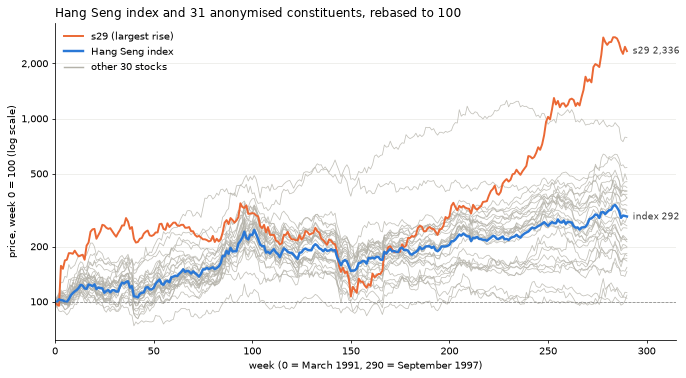

Text summary: the index ends at 292 (start = 100). 31 of 31 stocks end above 100; the median stock ends at 259; 14 stocks end above the index. Largest rise: s29 at 2,336; smallest: s14 at 104.


In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter

rebased = df[series] / df[series].iloc[0] * 100
final = rebased.iloc[-1]
top = final[market.names].idxmax()

fig, ax = plt.subplots(figsize=(10, 5.5))
for name in market.names:
    if name != top:
        ax.plot(rebased.index, rebased[name], color="#b4b2a9", linewidth=0.8, alpha=0.8)
ax.plot(rebased.index, rebased[top], color="#eb6834", linewidth=2, label=f"{top} (largest rise)")
ax.plot(rebased.index, rebased["index"], color="#2a78d6", linewidth=2.5, label="Hang Seng index")
ax.plot([], [], color="#b4b2a9", linewidth=1.5, label="other 30 stocks")

ax.set_yscale("log")
ax.yaxis.set_major_locator(FixedLocator([50, 100, 200, 500, 1000, 2000]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_locator(FixedLocator([]))
for name, color in [(top, "#eb6834"), ("index", "#2a78d6")]:
    label = "index" if name == "index" else name
    ax.annotate(f"{label} {final[name]:,.0f}", (rebased.index[-1], final[name]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.axhline(100, color="#888888", linewidth=0.8, linestyle="--")
ax.set_xlim(0, rebased.index[-1] + 25)
ax.set_xlabel("week (0 = March 1991, 290 = September 1997)")
ax.set_ylabel("price, week 0 = 100 (log scale)")
ax.set_title("Hang Seng index and 31 anonymised constituents, rebased to 100", loc="left")
ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

stocks_final = final[market.names]
print(f"Text summary: the index ends at {final['index']:.0f} (start = 100). "
      f"{(stocks_final > 100).sum()} of {len(stocks_final)} stocks end above 100; the median stock ends at "
      f"{stocks_final.median():.0f}; {(stocks_final > final['index']).sum()} stocks end above the index. "
      f"Largest rise: {stocks_final.idxmax()} at {stocks_final.max():,.0f}; smallest: "
      f"{stocks_final.idxmin()} at {stocks_final.min():.0f}.")

**How to read this chart (Hang Seng)**
- **X axis:** week number, from week 0 (March 1991) to week 290 (September 1997).
- **Y axis:** price, with every series starting at 100 in week 0. Log scale: each step up the axis is a multiplication, so a doubling looks the same size everywhere.
- **Lines:** grey = the 31 stocks, blue = the Hang Seng index, orange = the stock that rose the most.
- **Conclusion:** a strong rising market. The index almost tripled (ends at 292), every stock ended above its start, and s29 rose about 23 times (ends at 2,336).

## Kaggle dataset: named US stocks and ETFs (first look)

Source: Boris Marjanovic, *Huge Stock Market Dataset*, Kaggle, licence **CC0 (public domain)**. Daily prices of US stocks and ETFs (exchange-traded funds), adjusted for dividends and splits, up to 10 Nov 2017. Downloaded 2026-10-10 to `data/raw/kaggle/archive.zip`. The archive is 515 MB, so it is **not in git**; we will ship only a small CSV of the assets we choose. To get it, no login needed:

`curl -L -o data/raw/kaggle/archive.zip https://www.kaggle.com/api/v1/datasets/download/borismarjanovic/price-volume-data-for-all-us-stocks-etfs`

The archive contains every file twice (`Data/ETFs` = `ETFs`, `Data/Stocks` = `Stocks`, identical checksums); we read `ETFs/` and `Stocks/` only.

### K.1 What is in the archive

In [11]:
import zipfile
from stocks import kaggle_data

KAGGLE_ZIP = kaggle_data.ARCHIVE_PATH
ARCHIVE_AVAILABLE = KAGGLE_ZIP.is_file()
if not ARCHIVE_AVAILABLE:
    print(f"{KAGGLE_ZIP.relative_to(ROOT)} not found: K.1-K.3 explore the raw archive and are skipped. "
          "Task 2 below runs from the shipped data/kaggle_weekly_29.csv.")
else:
    zf = zipfile.ZipFile(KAGGLE_ZIP)

    rows = []
    for info in zf.infolist():
        folder, _, filename = info.filename.partition("/")
        if folder not in ("ETFs", "Stocks") or not filename.endswith(".us.txt"):
            continue
        ticker = filename.removesuffix(".us.txt").upper()
        lines = zf.read(info).decode().splitlines() if info.file_size else []
        if len(lines) > 1:
            rows.append((ticker, folder, lines[1][:10], lines[-1][:10], len(lines) - 1))
        else:
            rows.append((ticker, folder, None, None, 0))
    inventory = pd.DataFrame(rows, columns=["ticker", "type", "first day", "last day", "trading days"])

    has_data = inventory["trading days"] > 0
    overview = inventory.groupby("type").agg(
        files=("ticker", "size"),
        empty_files=("trading days", lambda d: int((d == 0).sum())),
        earliest_day=("first day", "min"),
        latest_day=("last day", "max"),
        median_trading_days=("trading days", lambda d: int(d[d > 0].median())),
    )
    print(f"{len(inventory):,} files: {has_data.sum():,} with prices, {(~has_data).sum()} empty")
    display(overview)

8,539 files: 8,507 with prices, 32 empty


,files,empty_files,earliest_day,latest_day,median_trading_days
type,,,,,
ETFs,1344,0,1999-03-10,2017-11-10,1923
Stocks,7195,32,1962-01-02,2017-11-10,1818


### K.2 Asset universe: 29 named assets, one per qubit

IonQ's Forte 1 noise-model simulator on Qollab has **29 qubits**, and each asset is one qubit, so the universe is 29 assets. **SPY** (the whole US market) is kept outside as the market reference, like the index column in the Hang Seng data.

**Selection rule:** one to five well-known names per sector, chosen **only by sector and by having prices for the whole window**, not by how they performed. Known bias: these are companies that still existed in 2017 (survivorship bias), so returns look better than a fund would really have had. Company and fund names are added by us from the ticker symbols; the dataset only has tickers.

The **2008 crash** column is the change from the week before Lehman Brothers failed (Fri 12 Sep 2008) to the week before the stock-market low (Fri 6 Mar 2009), using weekly (Friday) closing prices.

In [12]:
IONQ_MAX_QUBITS = kaggle_data.MAX_QUBITS  # 29 = IonQ Forte 1 noise-model simulator on Qollab
BENCHMARK = kaggle_data.BENCHMARK[0]
# the frozen universe lives in stocks/kaggle_data.py (single source for notebook, tests and Qollab)
assets = pd.DataFrame(kaggle_data.UNIVERSE, columns=["ticker", "name", "group"]).set_index("ticker")
assert len(assets) == IONQ_MAX_QUBITS, f"{len(assets)} assets for {IONQ_MAX_QUBITS} qubits"

if ARCHIVE_AVAILABLE:
    tickers = list(assets.index) + [BENCHMARK]
    known = set(inventory.loc[inventory["trading days"] > 0, "ticker"])
    missing = [t for t in tickers if t not in known]
    if missing:
        raise KeyError(f"no prices in the archive for {missing}")

    def read_close(ticker):
        """Daily adjusted closing prices of one ticker from the archive."""
        folder = inventory.set_index("ticker").loc[ticker, "type"]
        frame = pd.read_csv(zf.open(f"{folder}/{ticker.lower()}.us.txt"), parse_dates=["Date"], index_col="Date")
        return frame["Close"]

    daily = pd.DataFrame({t: read_close(t) for t in tickers})
    start = max(daily[t].first_valid_index() for t in tickers)
    end = min(daily[t].last_valid_index() for t in tickers)
    weekly = daily.loc[start:end].resample("W-FRI").last()
    gaps = int(weekly.isna().sum().sum())

    crash = weekly.asof(pd.Timestamp("2009-03-06")) / weekly.asof(pd.Timestamp("2008-09-12")) * 100 - 100
    listing = pd.concat([assets, pd.DataFrame({"name": ["SPDR S&P 500 fund (whole market)"],
                                               "group": ["Market reference (not a qubit)"]}, index=[BENCHMARK])])
    table = listing.assign(**{
        "type": inventory.set_index("ticker").loc[listing.index, "type"],
        "data from": [daily[t].first_valid_index().date() for t in listing.index],
        f"price {weekly.index[0].date()}": weekly.iloc[0],
        f"price {weekly.index[-1].date()}": weekly.iloc[-1],
        "change whole period (%)": (weekly.iloc[-1] / weekly.iloc[0] - 1) * 100,
        "2008 crash (%)": crash,
    })
    table.index.name = "ticker"
    print(f"{len(assets)} assets = {IONQ_MAX_QUBITS} qubits, in {assets['group'].nunique()} groups, plus {BENCHMARK} as market reference")
    print(f"Common window: {start.date()} to {end.date()} = {len(weekly)} weekly prices, missing weekly prices: {gaps}")
    display(table)
else:
    print("raw archive not present: showing the frozen universe only")
    display(assets)

29 assets = 29 qubits, in 10 groups, plus SPY as market reference
Common window: 2006-05-22 to 2017-11-10 = 599 weekly prices, missing weekly prices: 0


,name,group,type,data from,price 2006-05-26,price 2017-11-10,change whole period (%),2008 crash (%)
ticker,,,,,,,,
AAPL,Apple,Tech,Stocks,1984-09-07,8.14,174.67,"2,046.59",-42.73
MSFT,Microsoft,Tech,Stocks,1986-03-13,19.89,83.87,321.67,-44.67
INTC,Intel,Tech,Stocks,1972-01-07,14.61,45.58,211.96,-38.43
CSCO,Cisco Systems,Tech,Stocks,1990-03-26,16.78,33.99,102.59,-39.56
XLK,Technology Select Sector SPDR fund,Tech,ETFs,2005-02-25,18.46,63.50,244.04,-37.25
GLD,SPDR Gold Shares (gold),Gold & silver,ETFs,2005-02-25,65.10,121.13,86.07,22.16
SLV,iShares Silver Trust (silver),Gold & silver,ETFs,2006-04-28,12.67,15.95,25.89,22.60
GDX,VanEck Gold Miners fund,Gold & silver,ETFs,2006-05-22,37.02,22.52,-39.16,5.22
NEM,Newmont (gold miner),Gold & silver,Stocks,1983-04-06,47.08,35.52,-24.55,-1.92


### K.3 Price paths by group

Weekly closing prices rebased to 100 at the start of the common window, log scale. Each panel is one group; the dashed grey line is the whole market (SPY) for reference. The shaded band is the 2008 crash window from K.2.

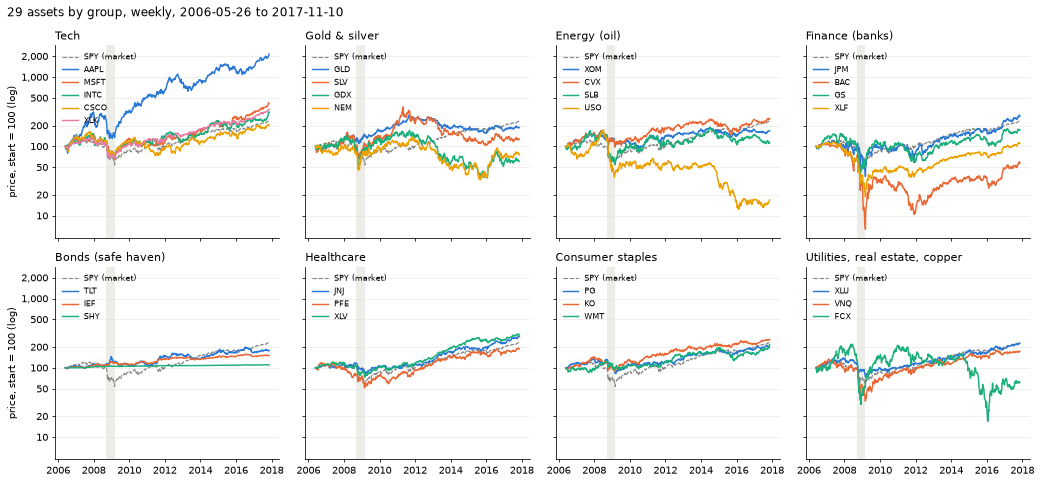

Text summary, average change per group in the 2008 crash window:
  Gold & silver                     4 assets   +12.0 %
  Bonds (safe haven)                3 assets    +5.4 %
  Consumer staples                  3 assets   -29.1 %
  Healthcare                        3 assets   -31.6 %
  Utilities                         1 assets   -36.5 %
  Tech                              5 assets   -40.5 %
  Energy (oil)                      4 assets   -43.1 %
  Market reference (not a qubit)    1 assets   -45.3 %
  Materials (copper)                1 assets   -54.1 %
  Real estate                       1 assets   -66.1 %
  Finance (banks)                   4 assets   -68.4 %


In [13]:
if ARCHIVE_AVAILABLE:
    palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
    panels = [("Tech", ["Tech"]), ("Gold & silver", ["Gold & silver"]), ("Energy (oil)", ["Energy (oil)"]),
              ("Finance (banks)", ["Finance (banks)"]), ("Bonds (safe haven)", ["Bonds (safe haven)"]),
              ("Healthcare", ["Healthcare"]), ("Consumer staples", ["Consumer staples"]),
              ("Utilities, real estate, copper", ["Utilities", "Real estate", "Materials (copper)"])]
    assert sum(len(assets[assets["group"].isin(g)]) for _, g in panels) == len(assets)
    rebased_k = weekly / weekly.iloc[0] * 100

    fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
    for ax, (title, groups) in zip(axes.flat, panels):
        ax.axvspan(pd.Timestamp("2008-09-12"), pd.Timestamp("2009-03-06"), color="#e5e4df", alpha=0.7, linewidth=0)
        ax.plot(rebased_k.index, rebased_k[BENCHMARK], color="#888888", linewidth=1.2, linestyle="--", label="SPY (market)")
        members = [t for t in assets.index if assets.loc[t, "group"] in groups]
        for color, ticker in zip(palette, members):
            ax.plot(rebased_k.index, rebased_k[ticker], color=color, linewidth=1.5, label=ticker)
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(FixedLocator([10, 20, 50, 100, 200, 500, 1000, 2000]))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.yaxis.set_minor_locator(FixedLocator([]))
        ax.set_title(title, loc="left", fontsize=11)
        ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", frameon=False, fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel("price, start = 100 (log)")
    fig.suptitle(f"29 assets by group, weekly, {weekly.index[0].date()} to {weekly.index[-1].date()}", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

    by_group = table.groupby("group", sort=False).agg(assets=("name", "size"), crash_avg=("2008 crash (%)", "mean"))
    print("Text summary, average change per group in the 2008 crash window:")
    for group, row in by_group.sort_values("crash_avg", ascending=False).iterrows():
        print(f"  {group:<32} {int(row['assets']):>2} assets  {row['crash_avg']:+6.1f} %")
else:
    print("raw archive not present: K.3 chart skipped")

**How to read this chart (Kaggle price paths)**
- **X axis:** date, May 2006 to November 2017.
- **Y axis:** price, with every asset starting at 100. Log scale, so 200 = doubled and 50 = halved.
- **Each panel** is one group; the dashed grey line is the whole market (SPY); the shaded band is the 2008 crash.
- **Conclusion:** inside the crash band, tech, banks, energy and real estate fell hard, while gold, silver and bonds held up or rose (gold & silver +12 %, bonds +5 % on average). Apple grew far more than anything else; the oil fund USO lost most of its value.

### K.4 Which assets run at each size

Rule, fixed in advance and independent of performance: take **one asset from each group in turn** (groups and assets in the order of the K.2 table) until the size is reached. Every size keeps the groups balanced, and a smaller set is always contained in a larger one.

In [14]:
from stocks.kaggle_data import select_assets  # reusable, tested implementation

selection = {n: select_assets(n) for n in RUN_SIZES}
for n, picked in selection.items():
    print(f"{n:>2} qubits, {assets.loc[picked, 'group'].nunique()} groups: {', '.join(picked)}")

membership = pd.DataFrame({f"{n} qubits": ["✓" if t in selection[n] else "" for t in assets.index]
                           for n in RUN_SIZES}, index=assets.index)
membership.insert(0, "group", assets["group"])
membership

12 qubits, 10 groups: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV
29 qubits, 10 groups: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV, CVX, BAC, IEF, PFE, KO, INTC, GDX, SLB, GS, SHY, XLV, WMT, CSCO, NEM, USO, XLF, XLK


,group,12 qubits,29 qubits
ticker,,,
AAPL,Tech,✓,✓
MSFT,Tech,✓,✓
INTC,Tech,,✓
CSCO,Tech,,✓
XLK,Tech,,✓
GLD,Gold & silver,✓,✓
SLV,Gold & silver,✓,✓
GDX,Gold & silver,,✓
NEM,Gold & silver,,✓


## Task 2: returns, 70/30 split, covariance graph and risk–return diagnostics

Runs from the shipped files `data/kaggle_weekly_29.csv` and `data/kaggle_asset_metadata.csv` (the raw archive is not needed) and calls the reusable modules `stocks/kaggle_data.py`, `stocks/returns.py`, `stocks/graph.py` and `stocks/objective.py`. All estimates use the **training rows only**; the test block (last 30 %) is kept for later evaluation. No Ising encoding, Max-Cut, QAOA or optimisation in this task.

### 2.A Settings and asset universe

Shows the settings from the top cell and the assets selected for each size. SPY is the benchmark and never a qubit.

In [15]:
import numpy as np
from stocks import graph, kaggle_data, objective, returns, task2_report

print(f"QUBITS_SMALL = {QUBITS_SMALL}, QUBITS_LARGE = {QUBITS_LARGE}, RUN_SIZES = {RUN_SIZES}")
print(f"TRAIN_FRACTION = {TRAIN_FRACTION}, RISK_RETURN_WEIGHT (eta) = {RISK_RETURN_WEIGHT}  (provisional, not tuned)")
selected = {n: kaggle_data.select_assets(n) for n in RUN_SIZES}
for n, tickers in selected.items():
    print(f"n = {n}: {', '.join(tickers)}")
print("SPY excluded from every selection:", all(kaggle_data.BENCHMARK[0] not in t for t in selected.values()))
small, large = min(RUN_SIZES), max(RUN_SIZES)
print(f"n = {small} is the first {small} of n = {large}:", selected[small] == selected[large][:small])

QUBITS_SMALL = 12, QUBITS_LARGE = 29, RUN_SIZES = [12, 29]
TRAIN_FRACTION = 0.7, RISK_RETURN_WEIGHT (eta) = 1.0  (provisional, not tuned)
n = 12: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV
n = 29: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV, CVX, BAC, IEF, PFE, KO, INTC, GDX, SLB, GS, SHY, XLV, WMT, CSCO, NEM, USO, XLF, XLK
SPY excluded from every selection: True
n = 12 is the first 12 of n = 29: True


### 2.B Load the shipped weekly data

Loads `data/kaggle_weekly_29.csv` with the reusable loader, which checks the columns, the weekly date order and that prices are finite and positive. If the raw archive is present, it also confirms the CSV equals the pandas result of section K.2.

In [16]:
kw = kaggle_data.load_csv()
meta = kaggle_data.load_metadata()
print(f"shape: {kw.prices.shape[0]} weeks x {kw.prices.shape[1]} price series (plus the date column)")
print(f"dates: {kw.dates[0]} to {kw.dates[-1]} (week-ending Fridays)")
print(f"missing prices: {int(np.isnan(kw.prices).sum())}, non-positive prices: {int((kw.prices <= 0).sum())}")
print(f"columns: date, {', '.join(kw.tickers)}")
print(f"file size: {kaggle_data.CSV_PATH.stat().st_size:,} bytes (Qollab limit 2,000,000)")
print(f"metadata: {sum(m['is_qubit'] == 'true' for m in meta)} qubit assets + "
      f"{sum(m['role'] == 'benchmark' for m in meta)} benchmark ({meta[-1]['ticker']})")
size = f", {KAGGLE_ZIP.stat().st_size:,} bytes, gitignored, not shipped" if ARCHIVE_AVAILABLE else ""
print(f"raw archive present: {ARCHIVE_AVAILABLE}{size}")
if ARCHIVE_AVAILABLE:
    same = (list(weekly.columns) == kw.tickers
            and np.array_equal(weekly.index.values.astype("datetime64[D]"), kw.dates)
            and np.array_equal(weekly.to_numpy(), kw.prices))
    print("identical to the K.2 pandas result (resample W-FRI, last close):", same)

shape: 599 weeks x 30 price series (plus the date column)
dates: 2006-05-26 to 2017-11-10 (week-ending Fridays)
missing prices: 0, non-positive prices: 0
columns: date, AAPL, MSFT, INTC, CSCO, XLK, GLD, SLV, GDX, NEM, XOM, CVX, SLB, USO, JPM, BAC, GS, XLF, TLT, IEF, SHY, JNJ, PFE, XLV, PG, KO, WMT, XLU, VNQ, FCX, SPY
file size: 128,844 bytes (Qollab limit 2,000,000)
metadata: 29 qubit assets + 1 benchmark (SPY)
raw archive present: True, 515,591,518 bytes, gitignored, not shipped
identical to the K.2 pandas result (resample W-FRI, last close): True


### 2.C Weekly log returns and the chronological 70/30 split

r[t] = ln(P[t] / P[t-1]); each return is labelled with the week it ends. Training = the first floor(0.70 × rows) returns, test = the rest, never shuffled. Checks that the 2008 crash window (Fri 12 Sep 2008 to Fri 6 Mar 2009) lies inside training.

In [17]:
r_all = returns.log_returns(kw.prices)
r_dates = kw.dates[1:]
split = returns.chronological_split(len(r_all), TRAIN_FRACTION)
train_dates, test_dates = r_dates[split.train], r_dates[split.test]
print(f"price rows: {len(kw.dates)}, return rows: {len(r_all)}")
print(f"train: {len(train_dates)} rows ({len(train_dates) / len(r_all):.1%}), {train_dates[0]} to {train_dates[-1]}")
print(f"test:  {len(test_dates)} rows ({len(test_dates) / len(r_all):.1%}), {test_dates[0]} to {test_dates[-1]}")
crash_rows = returns.window_rows(r_dates)
print(f"2008 crash: returns ending {r_dates[crash_rows[0]]} to {r_dates[crash_rows[-1]]} = rows "
      f"{crash_rows[0]}..{crash_rows[-1]} ({len(crash_rows)} weeks); all in training: "
      f"{bool(np.all(crash_rows < split.split_index))}")
print("Everything below uses training rows only.")

price rows: 599, return rows: 598
train: 418 rows (69.9%), 2006-06-02 to 2014-05-30
test:  180 rows (30.1%), 2014-06-06 to 2017-11-10
2008 crash: returns ending 2008-09-19 to 2009-03-06 = rows 120..144 (25 weeks); all in training: True
Everything below uses training rows only.


### 2.D Training statistics for each size

mu = mean weekly log return, C = sample covariance (ddof = 1), rho = Pearson correlation, all from the same training rows. SPY is not an input here. The table lists every asset once (estimates do not depend on the size).

In [18]:
train_stats = {}
for n in RUN_SIZES:
    tickers = selected[n]
    columns = [kw.tickers.index(t) for t in tickers]
    st = graph.training_stats(r_all[split.train][:, columns], tickers)
    train_stats[n] = st
    off = st.corr[np.triu_indices(n, 1)]
    print(f"n = {n}: {st.n_obs} training returns, {train_dates[0]} to {train_dates[-1]}")
    print(f"  checks: {graph.matrix_checks(st)}")
    print(f"  variances (diag C): {np.diag(st.cov).min():.2e} to {np.diag(st.cov).max():.2e}; correlations: "
          f"min {off.min():+.2f}, mean {off.mean():+.2f}, max {off.max():+.2f}")

st_large = train_stats[large]
mu_table = pd.DataFrame({
    "group": [kaggle_data.GROUP_OF[t] for t in st_large.tickers],
    f"in n={small}": ["✓" if t in selected[small] else "" for t in st_large.tickers],
    "mu, weekly (%)": st_large.mu * 100,
    "volatility, weekly (%)": np.sqrt(np.diag(st_large.cov)) * 100,
}, index=pd.Index(st_large.tickers, name="ticker"))
with pd.option_context("display.float_format", "{:.3f}".format):
    display(mu_table)

n = 12: 418 training returns, 2006-06-02 to 2014-05-30
  checks: {'shape_ok': True, 'finite': True, 'cov_symmetric': True, 'corr_symmetric': True, 'cov_diag_nonnegative': True, 'corr_diag_max_deviation': 2.220446049250313e-16, 'corr_within_bounds': True}
  variances (diag C): 3.96e-04 to 5.10e-03; correlations: min -0.42, mean +0.23, max +0.81
n = 29: 418 training returns, 2006-06-02 to 2014-05-30
  checks: {'shape_ok': True, 'finite': True, 'cov_symmetric': True, 'corr_symmetric': True, 'cov_diag_nonnegative': True, 'corr_diag_max_deviation': 2.220446049250313e-16, 'corr_within_bounds': True}
  variances (diag C): 3.93e-06 to 7.32e-03; correlations: min -0.45, mean +0.27, max +0.90


,group,in n=12,"mu, weekly (%)","volatility, weekly (%)"
ticker,,,,
AAPL,Tech,✓,0.561,4.919
GLD,Gold & silver,✓,0.147,2.785
XOM,Energy (oil),✓,0.139,3.006
JPM,Finance (banks),✓,0.082,6.154
TLT,Bonds (safe haven),✓,0.097,1.990
JNJ,Healthcare,✓,0.151,2.190
PG,Consumer staples,✓,0.116,2.347
XLU,Utilities,✓,0.103,2.491
VNQ,Real estate,✓,0.066,4.415


**Plot 2.D: risk vs average gain per asset.** Each dot is one asset: further right = moves up and down more (riskier), higher = earned more per week on average in the learning period. Filled dots are in the 12-asset run.

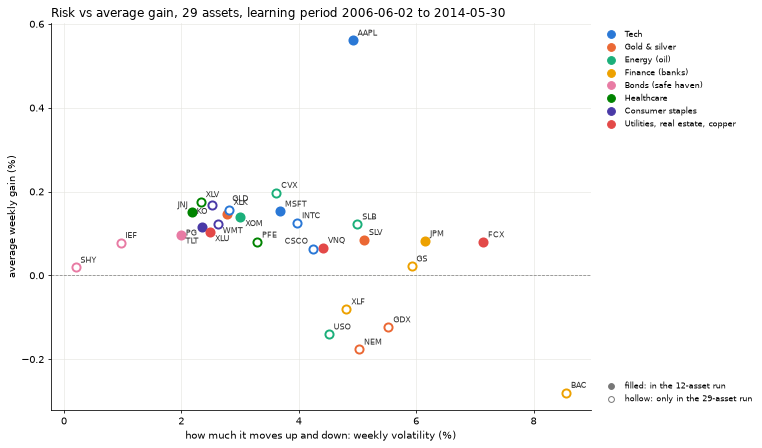

Text summary: highest average gain AAPL (+0.56 %/week), lowest BAC (-0.28 %/week); calmest SHY (0.20 %), most volatile BAC (8.55 %). 5 of 29 assets lost money on average in the learning period: BAC, GDX, NEM, USO, XLF.


In [19]:
from matplotlib.lines import Line2D

# group colours: 8 palette slots in fixed order; the three one-asset groups share "utilities, real estate, copper"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
OTHER = ("Utilities", "Real estate", "Materials (copper)")
OTHER_LABEL = "Utilities, real estate, copper"
GROUP_COLOR = dict(zip([g for g in kaggle_data.GROUPS if g not in OTHER] + [OTHER_LABEL], SLOTS))
BROWN, TEAL = "#a6611a", "#018571"  # ends of the BrBG palette used in the heatmaps

def color_of(ticker):
    group = kaggle_data.GROUP_OF[ticker]
    return GROUP_COLOR[OTHER_LABEL if group in OTHER else group]

def place_labels(ax, xs, ys, labels, fontsize=8):
    """Put each label next to its dot, trying a few positions so labels do not overlap dots or each other."""
    ax.figure.canvas.draw()
    to_pt = 72 / ax.figure.dpi
    pts = [ax.transData.transform((x, y)) * to_pt for x, y in zip(xs, ys)]
    options = [(5, 3), (5, -11), (-5, 3), (-5, -11), (5, 11), (-5, 11), (5, -19), (-5, -19)]
    boxes = []
    for k in np.argsort(xs):
        x0, y0 = pts[k]
        width = 0.62 * fontsize * len(labels[k])
        def box(dx, dy):
            left = x0 + dx if dx > 0 else x0 + dx - width
            return left, y0 + dy, left + width, y0 + dy + fontsize
        def free(b):
            clear_boxes = all(b[2] < o[0] or b[0] > o[2] or b[3] < o[1] or b[1] > o[3] for o in boxes)
            clear_dots = all(not (b[0] - 4 < px < b[2] + 4 and b[1] - 4 < py < b[3] + 4)
                             for j, (px, py) in enumerate(pts) if j != k)
            return clear_boxes and clear_dots
        dx, dy = next((o for o in options if free(box(*o))), options[0])
        boxes.append(box(dx, dy))
        ax.annotate(labels[k], (xs[k], ys[k]), xytext=(dx, dy), textcoords="offset points", fontsize=fontsize,
                    ha="left" if dx > 0 else "right", va="bottom", color="#333333")

def group_legend(ax, **kwargs):
    handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=c, label=g) for g, c in GROUP_COLOR.items()]
    return ax.legend(handles=handles, frameon=False, fontsize=8, **kwargs)

st = train_stats[large]
vol, gain = np.sqrt(np.diag(st.cov)) * 100, st.mu * 100
fig, ax = plt.subplots(figsize=(11, 6.5))
for t, x, y in zip(st.tickers, vol, gain):
    filled = t in selected[small]
    ax.scatter(x, y, s=70, color=color_of(t) if filled else "white", edgecolor=color_of(t), linewidth=2, zorder=3)
ax.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
ax.set_xlabel("how much it moves up and down: weekly volatility (%)")
ax.set_ylabel("average weekly gain (%)")
ax.set_title(f"Risk vs average gain, {large} assets, learning period {train_dates[0]} to {train_dates[-1]}", loc="left")
ax.grid(True, color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
legend = group_legend(ax, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.add_artist(legend)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color="#777777", label=f"filled: in the {small}-asset run"),
                   Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="#777777",
                          label=f"hollow: only in the {large}-asset run")],
          frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(1.01, 0))
fig.tight_layout()
place_labels(ax, vol, gain, st.tickers)
plt.show()

k_gain, k_loss, k_calm, k_wild = np.argmax(gain), np.argmin(gain), np.argmin(vol), np.argmax(vol)
print(f"Text summary: highest average gain {st.tickers[k_gain]} ({gain[k_gain]:+.2f} %/week), lowest "
      f"{st.tickers[k_loss]} ({gain[k_loss]:+.2f} %/week); calmest {st.tickers[k_calm]} ({vol[k_calm]:.2f} %), "
      f"most volatile {st.tickers[k_wild]} ({vol[k_wild]:.2f} %). {int((gain < 0).sum())} of {large} assets "
      f"lost money on average in the learning period: {', '.join(t for t, g in zip(st.tickers, gain) if g < 0)}.")

**How to read this chart (risk vs gain)**
- **X axis:** how much the asset moves up and down in a typical week (weekly volatility, %). Further right = riskier.
- **Y axis:** its average gain per week (%) in the learning period. Higher = earned more. Below the dashed line = lost money.
- **Dots:** colour = group; filled = also in the 12-asset run, hollow = only in the 29-asset run.
- **Conclusion:** more risk did **not** mean more gain here. Bonds sit far left (very calm, small gains); Apple is the clear winner (+0.56 %/week); Bank of America is the riskiest **and** lost the most; 5 assets lost money (BAC, GDX, NEM, USO, XLF).

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

### 2.E Negative links and sparsification diagnostics

Negative links: pairs with C_ij < 0 (and rho_ij < 0). Sparsification is a diagnostic mask only: keep the ceil(0.30 × pairs) strongest links by |C_ij|, ties broken by pair index. The dense C stays the objective. The expected-return term belongs to single assets, not to edges, so it is not sparsified.

In [20]:
negative_tables = {}
for n in RUN_SIZES:
    st, tickers = train_stats[n], selected[n]
    groups = [kaggle_data.GROUP_OF[t] for t in tickers]
    neg = graph.negative_links(st, groups, list(kaggle_data.GROUPS))
    print(f"n = {n}: {neg['n_negative_cov']} of {neg['n_pairs']} pairs have C < 0, {neg['n_negative_corr']} have rho < 0, "
          f"sign disagreements: {len(neg['sign_disagreements'])}")
    print("  negative pairs by group pair:", "; ".join(f"{k} {v}" for k, v in neg["by_group_pair"]))
    most_negative, strongest = graph.extreme_correlations(st, groups, k=5)
    print("  most negative rho:", ", ".join(f"{p['a']}-{p['b']} {p['corr']:+.2f}" for p in most_negative))
    print("  strongest positive rho:", ", ".join(f"{p['a']}-{p['b']} {p['corr']:+.2f}" for p in strongest))
    sg = graph.sparsify(st.cov)
    rep = sg.report
    print(f"  sparse mask: {rep['keep_rule']}; kept {rep['kept_edges']}, dropped {rep['dropped_edges']}, density {rep['density']:.0%}")
    print(f"  threshold: smallest kept |C| {rep['smallest_kept_abs_cov']:.3e}, largest dropped |C| "
          f"{rep['largest_dropped_abs_cov']:.3e}, tie at threshold: {rep['tie_at_threshold']}")
    print(f"  dropped share of sum |C_ij|: {rep['dropped_abs_share']:.1%}; kept negative edges: {rep['kept_negative_edges']}; "
          f"isolated assets: {', '.join(tickers[k] for k in rep['isolated_nodes']) or 'none'}")
    print("  strongest kept edges:", ", ".join(f"{tickers[i]}-{tickers[j]} {st.cov[i, j]:.2e}" for i, j in sg.edges[:5]))
    print("  weakest kept edges:", ", ".join(f"{tickers[i]}-{tickers[j]} {st.cov[i, j]:.2e}" for i, j in sg.edges[-3:]))
    print("  kept edges by group pair:", "; ".join(f"{k} {v}" for k, v in graph.kept_group_pairs(sg, groups, list(kaggle_data.GROUPS))))
    print()
    negative_tables[n] = pd.DataFrame(neg["pairs"])[["a", "group_a", "b", "group_b", "cov", "corr"]]

for n, frame in negative_tables.items():
    print(f"All negative pairs, n = {n} (most negative first):")
    with pd.option_context("display.max_rows", 200, "display.float_format", "{:.2e}".format):
        display(frame)

n = 12: 14 of 66 pairs have C < 0, 14 have rho < 0, sign disagreements: 0
  negative pairs by group pair: Tech – Bonds (safe haven) 2; Bonds (safe haven) – Materials (copper) 1; Finance (banks) – Bonds (safe haven) 1; Energy (oil) – Bonds (safe haven) 1; Bonds (safe haven) – Real estate 1; Bonds (safe haven) – Healthcare 1; Bonds (safe haven) – Utilities 1; Bonds (safe haven) – Consumer staples 1; Gold & silver – Bonds (safe haven) 1; Gold & silver – Consumer staples 1; Tech – Gold & silver 1; Gold & silver – Healthcare 1; Gold & silver – Finance (banks) 1
  most negative rho: TLT-FCX -0.42, JPM-TLT -0.37, XOM-TLT -0.36, AAPL-TLT -0.31, TLT-VNQ -0.27
  strongest positive rho: GLD-SLV +0.81, XOM-XLU +0.67, JPM-VNQ +0.67, JNJ-XLU +0.61, JNJ-PG +0.59
  sparse mask: ceil(0.3 * 66) = 20 strongest |C_ij|, ties by pair index; kept 20, dropped 46, density 30%
  threshold: smallest kept |C| 5.193e-04, largest dropped |C| 5.182e-04, tie at threshold: False
  dropped share of sum |C_ij|: 38.1%; k

,a,group_a,b,group_b,cov,corr
0,TLT,Bonds (safe haven),FCX,Materials (copper),-5.92e-04,-4.17e-01
1,JPM,Finance (banks),TLT,Bonds (safe haven),-4.56e-04,-3.72e-01
2,XOM,Energy (oil),TLT,Bonds (safe haven),-2.14e-04,-3.57e-01
3,AAPL,Tech,TLT,Bonds (safe haven),-3.02e-04,-3.09e-01
4,TLT,Bonds (safe haven),VNQ,Real estate,-2.38e-04,-2.71e-01
5,TLT,Bonds (safe haven),MSFT,Tech,-1.72e-04,-2.35e-01
6,TLT,Bonds (safe haven),JNJ,Healthcare,-9.32e-05,-2.14e-01
7,TLT,Bonds (safe haven),XLU,Utilities,-9.89e-05,-2.00e-01
8,TLT,Bonds (safe haven),PG,Consumer staples,-8.19e-05,-1.75e-01
9,TLT,Bonds (safe haven),SLV,Gold & silver,-1.68e-04,-1.65e-01


All negative pairs, n = 29 (most negative first):


,a,group_a,b,group_b,cov,corr
0,TLT,Bonds (safe haven),XLK,Tech,-2.49e-04,-4.45e-01
1,TLT,Bonds (safe haven),FCX,Materials (copper),-5.92e-04,-4.17e-01
2,IEF,Bonds (safe haven),XLK,Tech,-1.07e-04,-3.96e-01
3,TLT,Bonds (safe haven),SLB,Energy (oil),-3.94e-04,-3.96e-01
4,TLT,Bonds (safe haven),XLF,Finance (banks),-3.76e-04,-3.93e-01
5,JPM,Finance (banks),TLT,Bonds (safe haven),-4.56e-04,-3.72e-01
6,XOM,Energy (oil),TLT,Bonds (safe haven),-2.14e-04,-3.57e-01
7,TLT,Bonds (safe haven),CVX,Energy (oil),-2.57e-04,-3.57e-01
8,SHY,Bonds (safe haven),XLK,Tech,-1.98e-05,-3.55e-01
9,IEF,Bonds (safe haven),XLF,Finance (banks),-1.61e-04,-3.48e-01


**Plot 2.E: the map of links, before and after thinning.** Assets sit on a circle, grouped. Left: only the opposite-direction links (the hedges, brown). Right: the links the 30 % thinning keeps (teal = same direction). A black ring marks an asset with no links left. The bar chart below counts the links each asset keeps.

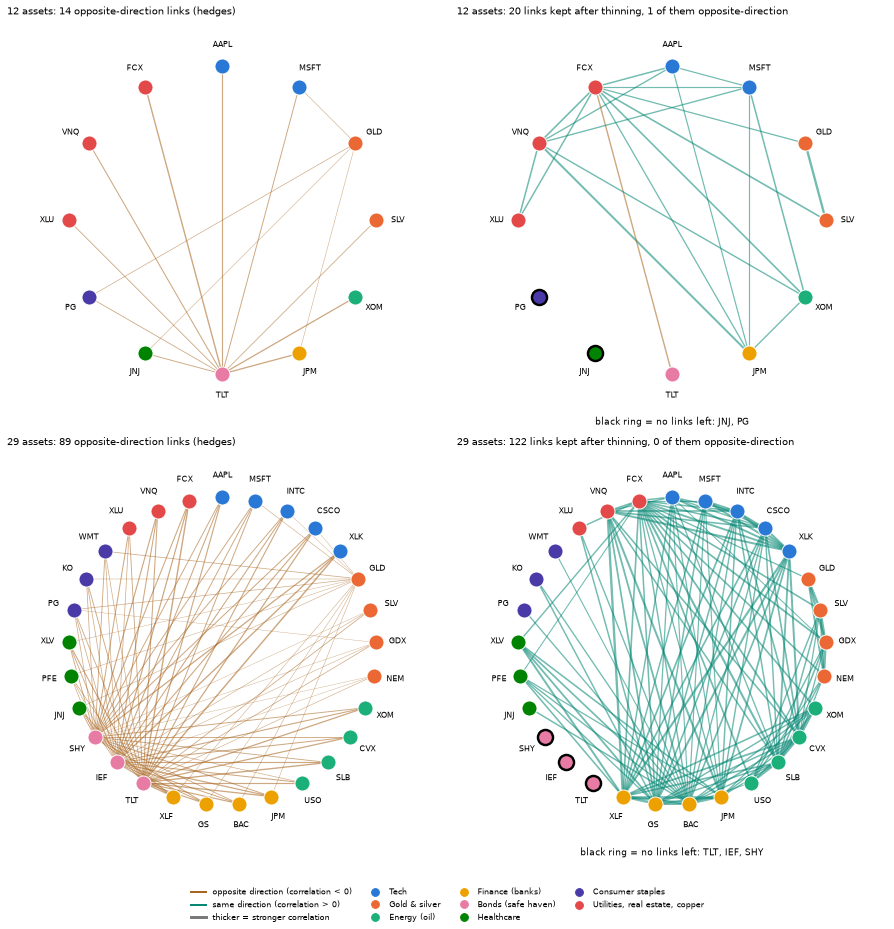

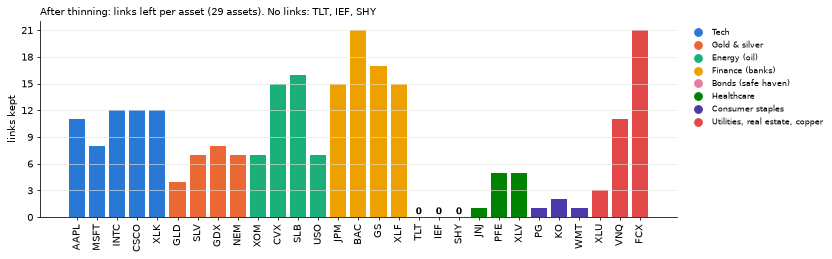

Text summary, 12 assets: 14 opposite-direction links before thinning, 1 after; assets left without links: JNJ, PG.
Text summary, 29 assets: 89 opposite-direction links before thinning, 0 after; assets left without links: TLT, IEF, SHY.


In [21]:
def circle_positions(tickers):
    order = [t for t in kaggle_data.TICKERS if t in tickers]  # grouped, frozen order
    angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(order), endpoint=False)
    return {t: (np.cos(a), np.sin(a)) for t, a in zip(order, angles)}

sparse_graphs = {n: graph.sparsify(train_stats[n].cov) for n in RUN_SIZES}
fig, axes = plt.subplots(len(RUN_SIZES), 2, figsize=(13, 6.6 * len(RUN_SIZES)), squeeze=False)
for row, n in enumerate(RUN_SIZES):
    st, tickers, sg = train_stats[n], selected[n], sparse_graphs[n]
    pos = circle_positions(tickers)
    iu, ju = np.triu_indices(n, 1)
    hedges = [(int(i), int(j)) for i, j in zip(iu, ju) if st.cov[i, j] < 0]
    isolated = {tickers[k] for k in sg.report["isolated_nodes"]}
    panels = [(f"{n} assets: {len(hedges)} opposite-direction links (hedges)", hedges, set()),
              (f"{n} assets: {len(sg.edges)} links kept after thinning, {sg.report['kept_negative_edges']} of them opposite-direction",
               sg.edges, isolated)]
    for ax, (title, edges, ringed) in zip(axes[row], panels):
        for i, j in edges:
            (x1, y1), (x2, y2) = pos[tickers[i]], pos[tickers[j]]
            ax.plot([x1, x2], [y1, y2], color=BROWN if st.cov[i, j] < 0 else TEAL,
                    linewidth=0.4 + 2.5 * abs(st.corr[i, j]), alpha=0.55, zorder=1)
        for t, (x, y) in pos.items():
            ax.scatter(x, y, s=240, color=color_of(t), edgecolor="black" if t in ringed else "white",
                       linewidth=2.5 if t in ringed else 1, zorder=3)
            ax.annotate(t, (1.14 * x, 1.14 * y), ha="center", va="center", fontsize=8)
        if ringed:
            ax.text(0, -1.33, "black ring = no links left: " + ", ".join(t for t in tickers if t in ringed),
                    ha="center", fontsize=9)
        ax.set_title(title, loc="left", fontsize=10)
        ax.set_aspect("equal")
        ax.set_xlim(-1.4, 1.4)
        ax.set_ylim(-1.42, 1.3)
        ax.axis("off")
link_handles = [Line2D([], [], color=BROWN, linewidth=2, label="opposite direction (correlation < 0)"),
                Line2D([], [], color=TEAL, linewidth=2, label="same direction (correlation > 0)"),
                Line2D([], [], color="#777777", linewidth=3, label="thicker = stronger correlation")]
fig.legend(handles=link_handles + [Line2D([], [], marker="o", linestyle="", markersize=8, color=c, label=g)
                                   for g, c in GROUP_COLOR.items()],
           loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

n = large
st, tickers, sg = train_stats[n], selected[n], sparse_graphs[n]
order = [t for t in kaggle_data.TICKERS if t in tickers]
degree = {t: int(sg.mask[tickers.index(t)].sum()) for t in order}
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(range(n), [degree[t] for t in order], color=[color_of(t) for t in order])
for k, t in enumerate(order):
    if degree[t] == 0:
        ax.annotate("0", (k, 0), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(n), order, rotation=90)
ax.set_ylabel("links kept")
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(f"After thinning: links left per asset ({n} assets). No links: "
             f"{', '.join(t for t in order if degree[t] == 0) or 'none'}", loc="left", fontsize=10)
ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
group_legend(ax, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

for n in RUN_SIZES:
    st, sg = train_stats[n], sparse_graphs[n]
    hedges = int((st.cov[np.triu_indices(n, 1)] < 0).sum())
    print(f"Text summary, {n} assets: {hedges} opposite-direction links before thinning, "
          f"{sg.report['kept_negative_edges']} after; assets left without links: "
          f"{', '.join(selected[n][k] for k in sg.report['isolated_nodes']) or 'none'}.")

**How to read these charts (the map of links)**
- **Circle maps:** there are no axes. Each dot is an asset (colour = group), placed around a circle by group. A line joins two assets: brown = they move in opposite directions, teal = they move together; thicker = stronger. Left = only the opposite-direction links (the hedges); right = the links kept after thinning to the strongest 30 %.
- **Bar chart:** X axis = the 29 assets (grouped); Y axis = how many links each asset keeps after thinning.
- **Conclusion:** almost all hedge links go to the bonds, but the thinning keeps **none** of them and leaves the three bonds (TLT, IEF, SHY) with zero links. Banks and copper keep the most links (21). So the thinning rule throws away exactly the protection we want and must be changed before the quantum step.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

### 2.F Correlation heatmaps (training window)

Assets are ordered by group (the frozen universe order) so that each group forms a block; thin lines separate the groups. Diverging brown–teal palette (colour-blind conscious), fixed scale −1 to +1. A text summary follows the plot.

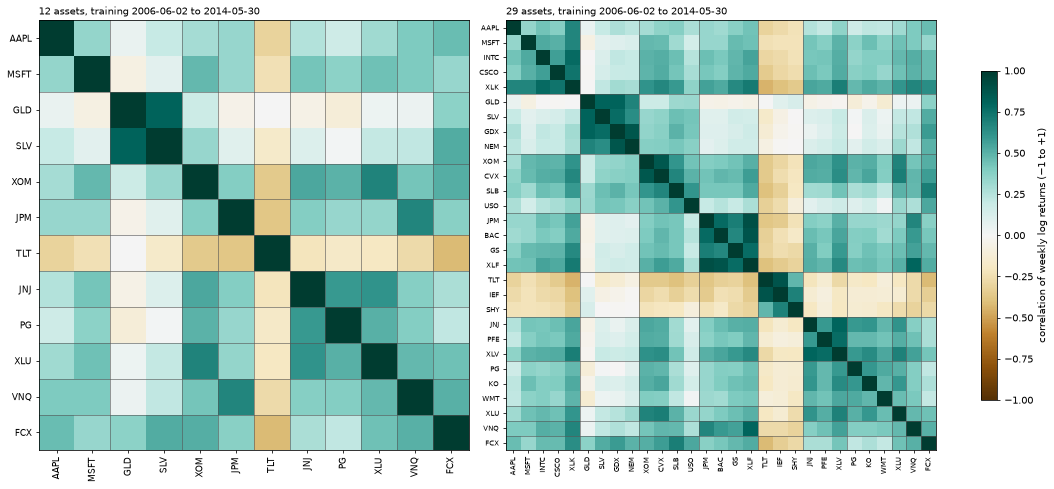

Text summary (training window):
  n = 12: mean correlation within groups +0.57, between groups +0.22; bonds vs other assets -0.25; gold & silver vs other assets +0.10; negative pairs 14 of 66
  n = 29: mean correlation within groups +0.66, between groups +0.23; bonds vs other assets -0.22; gold & silver vs other assets +0.14; negative pairs 89 of 406


In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(RUN_SIZES), figsize=(7.5 * len(RUN_SIZES), 6.8), squeeze=False, layout="constrained")
for ax, n in zip(axes[0], RUN_SIZES):
    st = train_stats[n]
    order = [t for t in kaggle_data.TICKERS if t in st.tickers]
    idx = [st.tickers.index(t) for t in order]
    image = ax.imshow(st.corr[np.ix_(idx, idx)], cmap="BrBG", vmin=-1, vmax=1)
    size = 7 if n > 15 else 9
    ax.set_xticks(range(n), order, rotation=90, fontsize=size)
    ax.set_yticks(range(n), order, fontsize=size)
    in_order = [kaggle_data.GROUP_OF[t] for t in order]
    for k in range(1, n):
        if in_order[k] != in_order[k - 1]:
            ax.axhline(k - 0.5, color="#555555", linewidth=0.6)
            ax.axvline(k - 0.5, color="#555555", linewidth=0.6)
    ax.set_title(f"{n} assets, training {train_dates[0]} to {train_dates[-1]}", loc="left", fontsize=10)
fig.colorbar(image, ax=axes[0].tolist(), shrink=0.75, label="correlation of weekly log returns (−1 to +1)")
plt.show()

print("Text summary (training window):")
for n in RUN_SIZES:
    st = train_stats[n]
    g = np.array([kaggle_data.GROUP_OF[t] for t in st.tickers])
    iu, ju = np.triu_indices(n, 1)
    same = g[iu] == g[ju]
    rho = st.corr[iu, ju]
    def vs_rest(group):
        pick = (g[iu] == group) ^ (g[ju] == group)
        return f"{rho[pick].mean():+.2f}" if pick.any() else "n/a"
    within = f"{rho[same].mean():+.2f}" if same.any() else "n/a"
    print(f"  n = {n}: mean correlation within groups {within}, between groups {rho[~same].mean():+.2f}; "
          f"bonds vs other assets {vs_rest('Bonds (safe haven)')}; gold & silver vs other assets "
          f"{vs_rest('Gold & silver')}; negative pairs {int((rho < 0).sum())} of {len(rho)}")

**How to read these heatmaps**
- **X axis and Y axis:** the same list of assets, grouped (lines separate the groups). Each square is the pair (row asset, column asset).
- **Colour:** correlation of their weekly moves, from −1 (brown, always opposite) through 0 (white, unrelated) to +1 (green, always together). The diagonal is each asset with itself (+1).
- **Conclusion:** green blocks along the diagonal = assets in the same group move together. The bond rows and columns are brown = bonds move against almost everything. The gold row is pale = gold is nearly unrelated to the other assets week to week.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

**Plot 2.F (simpler view): average correlation between groups.** One square per pair of groups, with the number written in it: +1 = always move together, 0 = unrelated, −1 = always opposite. A dash means the group has only one asset, so it has no 'within-group' value.

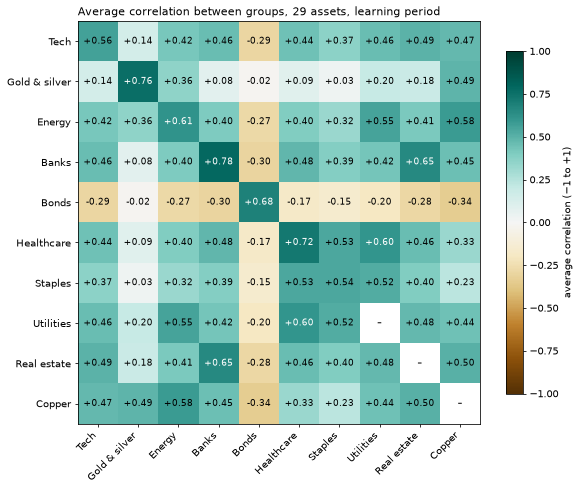

Text summary: most opposite pair of groups Bonds vs Copper (-0.34); most similar different groups Banks vs Real estate (+0.65).
9 of 45 pairs of different groups have a negative average; every one of them involves Bonds.


In [23]:
st = train_stats[large]
g = np.array([kaggle_data.GROUP_OF[t] for t in st.tickers])
present = [x for x in kaggle_data.GROUPS if x in g]
G = len(present)
avg = np.full((G, G), np.nan)
for a, ga in enumerate(present):
    for b, gb in enumerate(present):
        block = st.corr[np.ix_(np.flatnonzero(g == ga), np.flatnonzero(g == gb))]
        if a == b:
            if len(block) > 1:
                avg[a, b] = block[np.triu_indices(len(block), 1)].mean()
        else:
            avg[a, b] = block.mean()
short = {"Gold & silver": "Gold & silver", "Energy (oil)": "Energy", "Finance (banks)": "Banks",
         "Bonds (safe haven)": "Bonds", "Consumer staples": "Staples", "Materials (copper)": "Copper"}
labels = [short.get(x, x) for x in present]
fig, ax = plt.subplots(figsize=(8.5, 7.2))
image = ax.imshow(avg, cmap="BrBG", vmin=-1, vmax=1)
for a in range(G):
    for b in range(G):
        value = avg[a, b]
        text = "–" if np.isnan(value) else f"{value:+.2f}"
        ax.text(b, a, text, ha="center", va="center", fontsize=9, color="white" if abs(np.nan_to_num(value)) > 0.6 else "black")
ax.set_xticks(range(G), labels, rotation=45, ha="right")
ax.set_yticks(range(G), labels)
ax.set_title(f"Average correlation between groups, {large} assets, learning period", loc="left", fontsize=11)
fig.colorbar(image, ax=ax, shrink=0.8, label="average correlation (−1 to +1)")
fig.tight_layout()
plt.show()

between = [(avg[a, b], present[a], present[b]) for a in range(G) for b in range(a + 1, G)]
low, high = min(between), max(between)
print(f"Text summary: most opposite pair of groups {short.get(low[1], low[1])} vs {short.get(low[2], low[2])} "
      f"({low[0]:+.2f}); most similar different groups {short.get(high[1], high[1])} vs {short.get(high[2], high[2])} "
      f"({high[0]:+.2f}).")
negative = [{a_, b_} for v, a_, b_ in between if v < 0]
common = set.intersection(*negative) if negative else set()
print(f"{len(negative)} of {len(between)} pairs of different groups have a negative average"
      + (f"; every one of them involves {', '.join(short.get(x, x) for x in common)}." if common else "."))

**How to read this chart (groups)**
- **X axis and Y axis:** the 10 groups. Each square = the average correlation between assets of the two groups; the number is written in the square.
- **Diagonal:** the average inside one group (a dash means the group has only one asset).
- **Conclusion:** the Bonds row is the only brown row: all 9 negative group pairs involve bonds (strongest: bonds vs copper −0.34). Gold is close to 0 with most groups. Banks and real estate move together the most (+0.65).

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

### 2.G Risk–return score for example spin patterns (not optimised)

For spins s_i = +1 (long) / −1 (short), weights s_i / n and training estimates:
E_p = (1/n) Σ mu_i s_i, V_p = (1/n²) sᵀ C s, and **J = V_p / V_ref − eta · E_p / sigma_ref** with V_ref = mean(diag C), sigma_ref = √V_ref. Lower J is preferred. eta = RISK_RETURN_WEIGHT = 1.0 is provisional.

Three fixed example patterns: all long; alternating +1/−1 in selection order; random with seed 2026. They show the size of each term; they are **not** recommended portfolios, and nothing is optimised. The eta table uses predeclared values on training data only and does not choose eta. Weighted log returns are a simplification: this is not a profit forecast or a full P&L model.

In [24]:
rows = []
for n in RUN_SIZES:
    st = train_stats[n]
    for label, spins in objective.example_spins(n).items():
        s = objective.risk_return_score(spins, st.mu, st.cov, RISK_RETURN_WEIGHT)
        rows.append({"n": n, "pattern": label, "longs": int((spins == 1).sum()), "shorts": int((spins == -1).sum()),
                     "V_p": s["variance"], "E_p": s["expected_return"], "V_ref": s["v_ref"],
                     "risk term V_p/V_ref": s["risk_term"], "return term eta*E_p/sigma_ref": s["return_term"],
                     "eta": s["eta"], "J": s["score"]})
examples = pd.DataFrame(rows).set_index(["n", "pattern"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(examples)

sensitivity = pd.DataFrame(
    {f"J, eta = {eta}": [objective.risk_return_score(spins, train_stats[n].mu, train_stats[n].cov, eta)["score"]
                         for n in RUN_SIZES for spins in objective.example_spins(n).values()]
     for eta in task2_report.ETA_SENSITIVITY}, index=examples.index)
print("Sensitivity to eta (training only, predeclared values, not used to choose eta):")
with pd.option_context("display.float_format", "{:+.4f}".format):
    display(sensitivity)

longs  shorts       V_p       E_p  \
n  pattern                                                                      
12 all long                                    12       0 0.0005199  0.001482   
   alternating (+1 first, selection order)      6       6 0.0001181 0.0004041   
   random (seed 2026)                           5       7 9.576e-05 9.483e-05   
29 all long                                    29       0 0.0005673 0.0007957   
   alternating (+1 first, selection order)     15      14 3.568e-05 0.0003973   
   random (seed 2026)                          16      13 4.156e-05 2.703e-07   

                                              V_ref  risk term V_p/V_ref  \
n  pattern                                                                 
12 all long                                0.001746               0.2978   
   alternating (+1 first, selection order) 0.001746              0.06761   
   random (seed 2026)                      0.001746              0.05484   
29 all long                                0.001818                0.312   
   alternating (+1 first, selection order) 0.001818              0.01962   
   random (seed 2026)                      0.001818              0.02286   

                                            return term eta*E_p/sigma_ref  \
n  pattern                                                                  
12 all long                                                       0.03548   
   alternating (+1 first, selection order)                        0.00967   
   random (seed 2026)                                            0.002269   
29 all long                                                       0.01866   
   alternating (+1 first, selection order)                       0.009316   
   random (seed 2026)                                           6.339e-06   

                                            eta       J  
n  pattern                                               
12 all long                                   1  0.2623  
   alternating (+1 first, selection order)    1 0.05794  
   random (seed 2026)                         1 0.05257  
29 all long                                   1  0.2933  
   alternating (+1 first, selection order)    1 0.01031  
   random (seed 2026)                         1 0.02285

Sensitivity to eta (training only, predeclared values, not used to choose eta):


J, eta = 0.25  J, eta = 0.5  \
n  pattern                                                                
12 all long                                       +0.2889       +0.2800   
   alternating (+1 first, selection order)        +0.0652       +0.0628   
   random (seed 2026)                             +0.0543       +0.0537   
29 all long                                       +0.3073       +0.3027   
   alternating (+1 first, selection order)        +0.0173       +0.0150   
   random (seed 2026)                             +0.0229       +0.0229   

                                            J, eta = 1.0  J, eta = 2.0  
n  pattern                                                              
12 all long                                      +0.2623       +0.2268  
   alternating (+1 first, selection order)       +0.0579       +0.0483  
   random (seed 2026)                            +0.0526       +0.0503  
29 all long                                      +0.2933       +0.2747  
   alternating (+1 first, selection order)       +0.0103       +0.0010  
   random (seed 2026)                            +0.0229       +0.0228

**Plot 2.G: what the score is made of.** For each example portfolio: the blue bar is the risk part (lower is better), the orange bar is the earnings part that is subtracted, the black diamond is the final score J. The second chart shows how J changes with the weight eta. Examples only, not optimised.

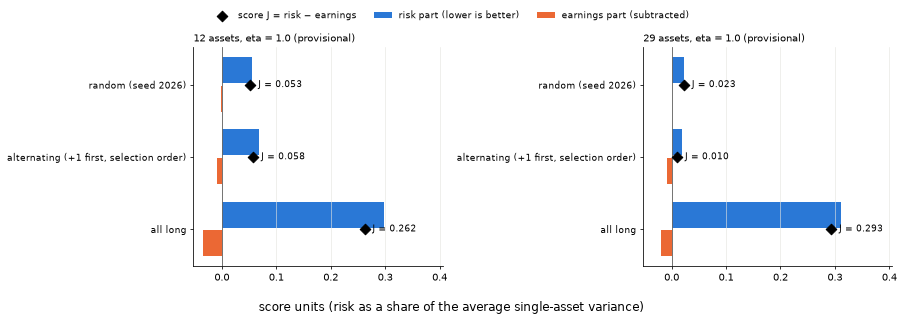

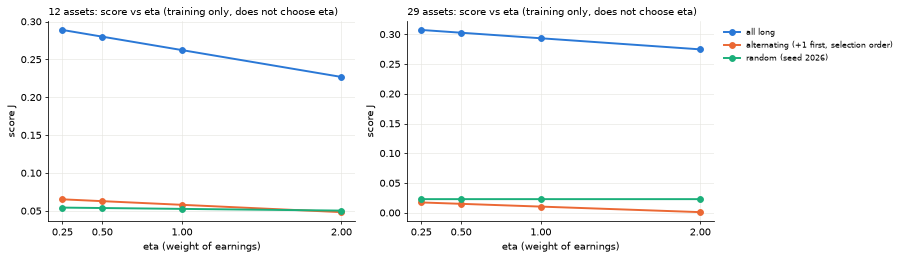

Text summary, 12 assets: lowest score among these three examples is 'random (seed 2026)' (J = 0.053); 'all long' has the highest risk part (0.298). These are examples, not optimised portfolios.
Text summary, 29 assets: lowest score among these three examples is 'alternating (+1 first, selection order)' (J = 0.010); 'all long' has the highest risk part (0.312). These are examples, not optimised portfolios.


In [25]:
fig, axes = plt.subplots(1, len(RUN_SIZES), figsize=(13, 4.2), sharex=True, squeeze=False)
for ax, n in zip(axes[0], RUN_SIZES):
    sub = examples.loc[n]
    y = np.arange(len(sub))
    ax.barh(y + 0.2, sub["risk term V_p/V_ref"], height=0.36, color="#2a78d6", label="risk part (lower is better)")
    ax.barh(y - 0.2, -sub["return term eta*E_p/sigma_ref"], height=0.36, color="#eb6834", label="earnings part (subtracted)")
    ax.scatter(sub["J"], y, marker="D", s=60, color="black", zorder=3, label="score J = risk − earnings")
    for yy, value in zip(y, sub["J"]):
        ax.annotate(f"J = {value:.3f}", (value, yy), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_yticks(y, sub.index, fontsize=9)
    ax.axvline(0, color="#555555", linewidth=0.8)
    ax.set_xlim(right=1.3 * max(sub["risk term V_p/V_ref"].max(), sub["J"].max()))
    ax.set_title(f"{n} assets, eta = {RISK_RETURN_WEIGHT} (provisional)", loc="left", fontsize=10)
    ax.grid(True, axis="x", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 1.07), ncol=3,
           frameon=False, fontsize=9)
fig.supxlabel("score units (risk as a share of the average single-asset variance)")
fig.tight_layout()
plt.show()

pattern_colors = dict(zip(examples.index.get_level_values("pattern").unique(), ["#2a78d6", "#eb6834", "#1baf7a"]))
fig, axes = plt.subplots(1, len(RUN_SIZES), figsize=(13, 3.8), squeeze=False)
etas = list(task2_report.ETA_SENSITIVITY)
for ax, n in zip(axes[0], RUN_SIZES):
    for label, spins in objective.example_spins(n).items():
        js = [objective.risk_return_score(spins, train_stats[n].mu, train_stats[n].cov, e)["score"] for e in etas]
        ax.plot(etas, js, marker="o", color=pattern_colors[label], linewidth=2, label=label)
    ax.set_xticks(etas)
    ax.set_xlabel("eta (weight of earnings)")
    ax.set_ylabel("score J")
    ax.set_title(f"{n} assets: score vs eta (training only, does not choose eta)", loc="left", fontsize=10)
    ax.grid(True, color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0][-1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

for n in RUN_SIZES:
    sub = examples.loc[n]
    lowest = sub["J"].idxmin()
    print(f"Text summary, {n} assets: lowest score among these three examples is '{lowest}' (J = {sub.loc[lowest, 'J']:.3f}); "
          f"'all long' has the highest risk part ({sub.loc['all long', 'risk term V_p/V_ref']:.3f}). "
          f"These are examples, not optimised portfolios.")

**How to read these charts (score)**
- **Bar chart:** X axis = score units (risk measured as a share of the average single asset's variance); Y axis = the three example portfolios. Blue bar = risk part (lower is better), orange bar = earnings part (subtracted, drawn to the left), black diamond = final score J = risk − earnings. Lower J is better.
- **Line chart:** X axis = eta, how much weight earnings get (0.25 to 2); Y axis = the score J.
- **Conclusion:** buying everything ('all long') carries much more risk (0.30) than mixing buys and sells (about 4 to 16 times less). The earnings part is small next to risk, so the lines are almost flat: changing eta hardly changes the order. These are examples, not optimised portfolios.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

### 2.H Task 2 report (also runs all unit tests)

Same output as `python -m stocks.task2_report` from the repo root.

In [26]:
task2_exit = task2_report.main(train_fraction=TRAIN_FRACTION, eta=RISK_RETURN_WEIGHT, sizes=tuple(RUN_SIZES))

[TASK 2] Kaggle returns, split, covariance graph, risk-return diagnostics
- CSV: data/kaggle_weekly_29.csv, 599 weeks x 30 series, 128,844 bytes, 2006-05-26 to 2017-11-10, missing or non-positive prices: 0
- Columns: date, AAPL, MSFT, INTC, CSCO, XLK, GLD, SLV, GDX, NEM, XOM, CVX, SLB, USO, JPM, BAC, GS, XLF, TLT, IEF, SHY, JNJ, PFE, XLV, PG, KO, WMT, XLU, VNQ, FCX, SPY
- Weekly log returns: 598 rows (2006-06-02 to 2017-11-10)
- Split (floor(0.7 x 598)): train 418 rows (69.9%) 2006-06-02 to 2014-05-30; test 180 rows (30.1%) 2014-06-06 to 2017-11-10
- 2008 crash (2008-09-12 to 2009-03-06): return rows 120..144 (25 weeks), all in training: yes
- n=12: AAPL, GLD, XOM, JPM, TLT, JNJ, PG, XLU, VNQ, FCX, MSFT, SLV
    training rows used for mu, C, rho: 418; matrix checks all pass: True
    negative links: 14 of 66 (cov) / 14 (corr), sign disagreements: 0
    by group pair (top): Tech – Bonds (safe haven) 2, Bonds (safe haven) – Materials (copper) 1, Finance (banks) – Bonds (safe haven) 1, En

- Tests (python -m unittest discover -s tests -t .): 94 passed, 0 failed, 0 skipped
RESULT: PASS


## Task 3: Ising encoding, exact and classical baselines

The score from Task 2 is rewritten as an **Ising energy** (the form a quantum computer works with), and solved with a normal computer so that the quantum result can be judged later. **Classical only: no circuits here.**

- **Mode A, long/short:** every asset is bought (+1) or shorted (−1, a bet against it).
- **Mode B, buy or skip:** every asset is bought (1) or not held (0); the unused money stays in cash.
- **Dial eta:** 0.25, 0.5, 1, 2 (low = play safe, high = chase past earnings). **Balance switch:** off / on.
- All 2 × 4 × 2 = 16 settings are run for each size and all are reported; nothing is chosen with test data.

### 3.A Settings, grid and the links that are kept

Builds the training statistics and the link mask for each size. Links are ranked by |correlation| (strong together **or** strong opposite), not by covariance as in 2.E.

In [27]:
from stocks import classical_evaluation, classical_solvers, ising, task3_report

ctx3 = task3_report.load_context(TRAIN_FRACTION)
setups3 = {n: task3_report.size_setup(ctx3, n, ising.keep_fraction_for(n, KEEP_FRACTION)) for n in RUN_SIZES}
grid3 = [(mode, balance, eta) for mode in ising.MODES for balance in task3_report.BALANCE_GRID for eta in ETA_GRID]
print(f"modes: {list(ising.MODES)}; eta: {list(ETA_GRID)}; balance: off / on -> {len(grid3)} configurations per size")
print("solver settings:", task3_report.SETTINGS)
for n, setup in setups3.items():
    rep, tickers, groups = setup["mask_report"], setup["tickers"], setup["groups"]
    print(f"\nn = {n}: {rep['rule']}")
    print(f"  kept {rep['kept_edges']}, dropped {rep['dropped_edges']}; opposite-direction links kept "
          f"{rep['kept_negative_edges']} of {rep['negative_edges_total']}; assets with no links: "
          f"{', '.join(tickers[k] for k in rep['isolated_nodes']) or 'none'}")
    if rep["dropped_edges"]:
        print(f"  threshold: weakest kept |rho| {rep['smallest_kept_abs_rho']:.3f}, strongest dropped |rho| "
              f"{rep['largest_dropped_abs_rho']:.3f}, tie at threshold: {rep['tie_at_threshold']}")
        strongest = sorted(rep["dropped_pairs"], key=lambda t: -abs(t[2]))[:5]
        print("  strongest dropped links:", ", ".join(f"{tickers[i]}-{tickers[j]} {r:+.2f}" for i, j, r in strongest))
        degree = setup["mask"].sum(axis=1)
        print(f"  links per asset after thinning: min {degree.min()} ({tickers[int(degree.argmin())]}), max {degree.max()} "
              f"({tickers[int(degree.argmax())]}); bonds: " + ", ".join(f"{t} {d}" for t, d, g in zip(tickers, degree, groups) if g.startswith("Bonds")))

modes: ['long_short', 'buy_or_skip']; eta: [0.25, 0.5, 1.0, 2.0]; balance: off / on -> 16 configurations per size
solver settings: {'seeds': (2026, 2027, 2028), 'random_samples': 1000, 'greedy_restarts': 30, 'sa_restarts': 30, 'sa_sweeps': 200, 'random_portfolios': 1000, 'portfolio_seed': 12345, 'penalty_max_n': 12}

n = 12: ceil(1.0 * 66) = 66 pairs with the largest |rho_ij|, ties by pair index
  kept 66, dropped 0; opposite-direction links kept 14 of 14; assets with no links: none

n = 29: ceil(0.6 * 406) = 244 pairs with the largest |rho_ij|, ties by pair index
  kept 244, dropped 162; opposite-direction links kept 18 of 89; assets with no links: none
  threshold: weakest kept |rho| 0.309, strongest dropped |rho| 0.307, tie at threshold: False
  strongest dropped links: PFE-SLB +0.31, VNQ-SHY -0.31, KO-SLB +0.31, MSFT-SLB +0.31, SHY-XLF -0.31
  links per asset after thinning: min 3 (SHY), max 25 (CVX); bonds: TLT 14, IEF 7, SHY 3


### 3.B The Ising models

One model per setting: `E(s) = Σ J_ij s_i s_j + Σ h_i s_i + const`. The table shows how many pair terms each model has, its constant and field range, and how balance is enforced: by a **penalty** in the model (12 assets, verified by enumeration) or by a **hard constraint** in the solvers (29 assets, no dense penalty).

In [28]:
rows = []
for n, setup in setups3.items():
    for mode, balance, eta in grid3:
        m = task3_report.build_model(setup, mode, eta, balance, TARGET_BUYS)
        rows.append({"n": n, "mode": mode, "eta": eta, "balance": "on" if balance else "off", "balance by": m.balance_method,
                     "target buys": "" if m.target_buys is None else m.target_buys, "lambda": m.penalty_lambda,
                     "pair terms": len(m.pair_terms()), "kept links": m.kept_edges, "const": m.const,
                     "field min": m.fields.min(), "field max": m.fields.max()})
models_table = pd.DataFrame(rows).set_index(["n", "mode", "balance", "eta"])
with pd.option_context("display.max_rows", 100, "display.float_format", "{:.4g}".format):
    display(models_table)

balance by target buys  lambda  pair terms  \
n  mode        balance eta                                                     
12 long_short  off     0.25             none                   0          66   
                       0.5              none                   0          66   
                       1                none                   0          66   
                       2                none                   0          66   
               on      0.25          penalty              0.0803          66   
                       0.5           penalty             0.08303          66   
                       1             penalty             0.08899          66   
                       2             penalty              0.1022          66   
   buy_or_skip off     0.25             none                   0          66   
                       0.5              none                   0          66   
                       1                none                   0          66   
                       2                none                   0          66   
               on      0.25          penalty           6 0.07752          66   
                       0.5           penalty           6  0.0754          66   
                       1             penalty           6 0.07226          66   
                       2             penalty           6 0.06842          66   
29 long_short  off     0.25             none                   0         244   
                       0.5              none                   0         244   
                       1                none                   0         244   
                       2                none                   0         244   
               on      0.25  hard_constraint                   0         244   
                       0.5   hard_constraint                   0         244   
                       1     hard_constraint                   0         244   
                       2     hard_constraint                   0         244   
   buy_or_skip off     0.25             none                   0         244   
                       0.5              none                   0         244   
                       1                none                   0         244   
                       2                none                   0         244   
               on      0.25  hard_constraint          14       0         244   
                       0.5   hard_constraint          14       0         244   
                       1     hard_constraint          14       0         244   
                       2     hard_constraint          14       0         244   

                             kept links   const  field min  field max  
n  mode        balance eta                                             
12 long_short  off     0.25          66 0.08333  -0.002796 -0.0003296  
                       0.5           66 0.08333  -0.005592 -0.0006592  
                       1             66 0.08333   -0.01118  -0.001318  
                       2             66 0.08333   -0.02237  -0.002637  
               on      0.25          66   1.047  -0.002796 -0.0003296  
                       0.5           66    1.08  -0.005592 -0.0006592  
                       1             66   1.151   -0.01118  -0.001318  
                       2             66   1.309   -0.02237  -0.002637  
   buy_or_skip off     0.25          66 0.09084  -0.004259    0.03069  
                       0.5           66  0.0864  -0.004501     0.0305  
                       1             66 0.07754  -0.004986     0.0301  
                       2             66  0.0598  -0.005955    0.02931  
               on      0.25          66   1.021  -0.004259    0.03069  
                       0.5           66  0.9913  -0.004501     0.0305  
                       1             66  0.9447  -0.004986     0.0301  
                       2             66  0.8808  -0.005955    0.02931  
29 long_short  of

### 3.C Checks: is the Ising energy really the score?

For 100 random states per case: (1) with all links, the Ising energy must equal the direct score; (2) with thinned links, it must equal the directly computed **sparse surrogate**; (3) the thinned energy is *not* the dense score, so both are always reported separately.

In [29]:
rng_check = np.random.default_rng(0)
for n, setup in setups3.items():
    st, mask = setup["stats"], setup["mask"]
    for mode in ising.MODES:
        dense_model = ising.build_ising(st.mu, st.cov, mode, RISK_RETURN_WEIGHT)
        thin_model = ising.build_ising(st.mu, st.cov, mode, RISK_RETURN_WEIGHT, keep_mask=mask)
        states = classical_solvers.random_spins(100, dense_model, rng_check)
        direct = ising.dense_scores(states, st.mu, st.cov, mode, RISK_RETURN_WEIGHT)
        surrogate = np.array([ising.sparse_surrogate_energy(s, st.mu, st.cov, mode, RISK_RETURN_WEIGHT, mask) for s in states])
        line = (f"n = {n}, {mode}: all links |Ising - score| max {np.abs(dense_model.energy(states) - direct).max():.1e}; "
                f"thinned |Ising - surrogate| max {np.abs(thin_model.energy(states) - surrogate).max():.1e}; "
                f"thinned vs dense score differ by up to {np.abs(thin_model.energy(states) - direct).max():.4f}")
        if mode == ising.MODE_LONG_SHORT:
            task2 = np.array([objective.risk_return_score(s, st.mu, st.cov, RISK_RETURN_WEIGHT)["score"] for s in states])
            line += f"; vs Task 2 score max {np.abs(dense_model.energy(states) - task2).max():.1e}"
        print(line)

n = 12, long_short: all links |Ising - score| max 1.1e-16; thinned |Ising - surrogate| max 1.1e-16; thinned vs dense score differ by up to 0.0000; vs Task 2 score max 8.3e-17
n = 12, buy_or_skip: all links |Ising - score| max 1.1e-16; thinned |Ising - surrogate| max 1.1e-16; thinned vs dense score differ by up to 0.0000
n = 29, long_short: all links |Ising - score| max 1.7e-16; thinned |Ising - surrogate| max 1.7e-16; thinned vs dense score differ by up to 0.0119; vs Task 2 score max 6.9e-17
n = 29, buy_or_skip: all links |Ising - score| max 1.7e-16; thinned |Ising - surrogate| max 1.4e-16; thinned vs dense score differ by up to 0.0037


### 3.D Run the whole grid; exact answers for 12 assets

Runs every setting for every size (about half a minute). For 12 assets all 2¹² = 4,096 portfolios are tried, so the answer is **exact**. The table shows the best portfolio of each setting, how many portfolios tie for best, and the check that the balance penalty works.

In [30]:
results3 = {n: [task3_report.run_configuration(setup, mode, eta, balance, TARGET_BUYS) for mode, balance, eta in grid3]
            for n, setup in setups3.items()}

def result_frame(n):
    frame = pd.DataFrame(results3[n])
    frame["balance"] = frame["balance"].map({False: "off", True: "on"})
    return frame.set_index(["mode", "balance", "eta"])

def assignment_text(r):
    a = r["assignment"]
    return ("long: " + ", ".join(a["long"]) + " | short: " + ", ".join(a["short"])) if r["mode"] == ising.MODE_LONG_SHORT \
        else ("buy: " + (", ".join(a["buy"]) or "nothing"))

for n in RUN_SIZES:
    if results3[n][0]["n_optimal"] is None:
        continue
    frame = result_frame(n)
    table = pd.DataFrame({
        "score (dense)": frame["dense_score"], "tied optima": frame["n_optimal"], "states tried": frame["n_states"],
        "allowed states": frame["search_space"],
        "penalty ok": [("" if c is None else c["ok"]) for c in frame["penalty_check"]],
        "portfolio": [assignment_text(r) for r in results3[n]],
    }, index=frame.index)
    print(f"n = {n}: exact optimum of every setting ({results3[n][0]['n_states']} states enumerated each)")
    with pd.option_context("display.max_colwidth", 200, "display.float_format", "{:+.5f}".format):
        display(table)

n = 12: exact optimum of every setting (4096 states enumerated each)


score (dense)  tied optima  states tried  \
mode        balance eta                                                  
long_short  off     +0.25000       +0.02606            1          4096   
                    +0.50000       +0.02317            1          4096   
                    +1.00000       +0.01535            1          4096   
                    +2.00000       -0.00526            1          4096   
            on      +0.25000       +0.02606            1          4096   
                    +0.50000       +0.02378            1          4096   
                    +1.00000       +0.01923            1          4096   
                    +2.00000       +0.00682            1          4096   
buy_or_skip off     +0.25000       +0.00000            1          4096   
                    +0.50000       +0.00000            1          4096   
                    +1.00000       -0.00433            1          4096   
                    +2.00000       -0.02263            1          4096   
            on      +0.25000       +0.02388            1          4096   
                    +0.50000       +0.01856            1          4096   
                    +1.00000       +0.00685            1          4096   
                    +2.00000       -0.01659            1          4096   

                              allowed states penalty ok  \
mode        balance eta                                   
long_short  off     +0.25000            4096              
                    +0.50000            4096              
                    +1.00000            4096              
                    +2.00000            4096              
            on      +0.25000             924       True   
                    +0.50000             924       True   
                    +1.00000             924       True   
                    +2.00000             924       True   
buy_or_skip off     +0.25000            4096              
                    +0.50000            4096              
                    +1.00000            4096              
                    +2.00000            4096              
            on      +0.25000             924       True   
                    +0.50000             924       True   
                    +1.00000             924       True   
                    +2.00000             924       True   

                                                                                              portfolio  
mode        balance eta                                                                                  
long_short  off     +0.25000  long: AAPL, XOM, JNJ, PG, VNQ, SLV | short: GLD, JPM, TLT, XLU, FCX, MSFT  
                    +0.50000  long: AAPL, XOM, JPM, TLT, PG, XLU, SLV | short: GLD, JNJ, VNQ, FCX, MSFT  
                    +1.00000  long: AAPL, GLD, JPM, TLT, PG, XLU, MSFT, SLV | short: XOM, JNJ, VNQ, FCX  
                    +2.00000  long: AAPL, GLD, JPM, TLT, JNJ, PG, XLU, MSFT, SLV | short: XOM, VNQ, FCX  
            on      +0.25000  long: AAPL, XOM, JNJ, PG, VNQ, SLV | short: GLD, JPM, TLT, XLU, FCX, MSFT  
                    +0.50000  long: AAPL, XOM, JNJ, PG, VNQ, SLV | short: GLD, JPM, TLT, XLU, FCX, MSFT  
                    +1.00000  long: AAPL, XOM, JNJ, PG, VNQ, SLV | short: GLD, JPM, TLT, XLU, FCX, MSFT  
                    +2.00000  long: AAPL, GLD, XOM, JNJ, VNQ, MSFT | short: JPM, TLT, PG, XLU, FCX, SLV  
buy_or_skip off     +0.25000                                                               buy: nothing  
                    +0.50000                                                               buy: nothing  
                    +1.00000                                                             buy: AAPL, TLT  
                    +2.00000                                                   buy: AAPL, GLD, TLT, JNJ  
            on      +0.25000                                          buy: GLD, TLT, JNJ, PG, XLU, MSFT  
                    +0.50000                

### 3.E Classical baselines for both sizes

Three simple solvers written by us: **random** (1,000 random portfolios), **greedy** (keep making the best single change until none helps) and **simulated annealing** (accepts some bad moves early, fewer later). 'Hit rate' = share of tries that reach the reference energy: the exact optimum for 12 assets, the **best found** for 29 assets (not proven optimal). For 29 assets the last columns show what the 60 % thinning costs on the true dense score.

In [31]:
for n in RUN_SIZES:
    frame = result_frame(n)
    exact_size = results3[n][0]["n_optimal"] is not None
    table = pd.DataFrame({
        "reference": frame["reference"],
        "model energy": frame["model_energy"], "dense score": frame["dense_score"],
        "random hit": [s["random"]["hit_rate_mean"] for s in frame["solvers"]],
        "greedy hit": [s["greedy"]["hit_rate_mean"] for s in frame["solvers"]],
        "annealing hit": [s["annealing"]["hit_rate_mean"] for s in frame["solvers"]],
        "seeds reaching it (rnd/grd/SA)": [f"{s['random']['seeds_reaching_reference']}/{s['greedy']['seeds_reaching_reference']}/"
                                           f"{s['annealing']['seeds_reaching_reference']} of {len(task3_report.SETTINGS['seeds'])}"
                                           for s in frame["solvers"]],
    }, index=frame.index)
    if exact_size:
        table["random best quality"] = [s["random"]["quality"] for s in frame["solvers"]]
    else:
        table["dense best found"] = frame["dense_best_found"]
        table["cost of thinning"] = frame["dense_score"] - frame["dense_best_found"]
    print(f"n = {n}: {'exact optimum known' if exact_size else 'BEST FOUND only (not proven optimal); balance by hard constraint'}")
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(table)

print(f"Portfolios at eta = {RISK_RETURN_WEIGHT}, by group:")
for n in RUN_SIZES:
    for r in results3[n]:
        if r["eta"] != RISK_RETURN_WEIGHT:
            continue
        plus = "long" if r["mode"] == ising.MODE_LONG_SHORT else "buy"
        chosen = set(r["assignment"][plus])
        by_group = "; ".join(f"{g}: {'+'.join(t for t in setups3[n]['tickers'] if kaggle_data.GROUP_OF[t] == g and t in chosen)}"
                             for g in kaggle_data.GROUPS if any(kaggle_data.GROUP_OF[t] == g for t in chosen))
        print(f"  n = {n}, {r['mode']}, balance {'on' if r['balance'] else 'off'}: {plus} {len(chosen)} of {n} -> {by_group or 'nothing'}")

n = 12: exact optimum known


reference  model energy  dense score  \
mode        balance eta                                                
long_short  off     0.2500  exact optimum        0.0261       0.0261   
                    0.5000  exact optimum        0.0232       0.0232   
                    1.0000  exact optimum        0.0154       0.0154   
                    2.0000  exact optimum       -0.0053      -0.0053   
            on      0.2500  exact optimum        0.0261       0.0261   
                    0.5000  exact optimum        0.0238       0.0238   
                    1.0000  exact optimum        0.0192       0.0192   
                    2.0000  exact optimum        0.0068       0.0068   
buy_or_skip off     0.2500  exact optimum        0.0000       0.0000   
                    0.5000  exact optimum        0.0000       0.0000   
                    1.0000  exact optimum       -0.0043      -0.0043   
                    2.0000  exact optimum       -0.0226      -0.0226   
            on      0.2500  exact optimum        0.0239       0.0239   
                    0.5000  exact optimum        0.0186       0.0186   
                    1.0000  exact optimum        0.0068       0.0068   
                    2.0000  exact optimum       -0.0166      -0.0166   

                            random hit  greedy hit  annealing hit  \
mode        balance eta                                             
long_short  off     0.2500      0.0000      0.0667         0.2000   
                    0.5000      0.0000      0.1000         0.2333   
                    1.0000      0.0000      0.0667         0.2556   
                    2.0000      0.0007      0.1333         0.4444   
            on      0.2500      0.0007      0.5000         0.6444   
                    0.5000      0.0007      0.4778         0.6444   
                    1.0000      0.0007      0.5889         0.5778   
                    2.0000      0.0007      0.5000         0.6111   
buy_or_skip off     0.2500      0.0000      1.0000         1.0000   
                    0.5000      0.0000      0.7778         0.9000   
                    1.0000      0.0000      1.0000         1.0000   
                    2.0000      0.0003      1.0000         1.0000   
            on      0.2500      0.0007      1.0000         1.0000   
                    0.5000      0.0020      1.0000         1.0000   
                    1.0000      0.0020      1.0000         1.0000   
                    2.0000      0.0020      1.0000         1.0000   

                           seeds reaching it (rnd/grd/SA)  random best quality  
mode        balance eta                                                         
long_short  off     0.2500                     0/3/3 of 3               0.9948  
                    0.5000                     0/2/3 of 3               0.9951  
                    1.0000                     0/3/3 of 3               0.9922  
                    2.0000                     2/3/3 of 3               1.0000  
            on      0.2500                     1/3/3 of 3               1.0000  
                    0.5000                     1/3/3 of 3               1.0000  
                    1.0000                     1/3/3 of 3               1.0000  
                    2.0000                     1/3/3 of 3               1.0000  
buy_or_skip off     0.2500                     0/3/3 of 3               0.9962  
                    0.5000                     0/3/3 of 3               0.9986  
                    1.0000                     0/3/3 of 3               0.9973  
                    2.0000                     1/3/3 of 3               1.0000  
            on      0.2500                     2/3/3 of 3               1.0000  
                    0.5000                     3/3/3 of 3               1.0000  
                    1.0000                     3/3/3 of 3               1.0000  
                    2.0000                     3/3/3 of 3               1.0000

n = 29: BEST FOUND only (not proven optimal); balance by hard constraint


reference  model energy  \
mode        balance eta                                                     
long_short  off     0.2500  best found (not proven optimal)       -0.0053   
                    0.5000  best found (not proven optimal)       -0.0093   
                    1.0000  best found (not proven optimal)       -0.0199   
                    2.0000  best found (not proven optimal)       -0.0438   
            on      0.2500  best found (not proven optimal)       -0.0051   
                    0.5000  best found (not proven optimal)       -0.0088   
                    1.0000  best found (not proven optimal)       -0.0181   
                    2.0000  best found (not proven optimal)       -0.0371   
buy_or_skip off     0.2500  best found (not proven optimal)       -0.0100   
                    0.5000  best found (not proven optimal)       -0.0109   
                    1.0000  best found (not proven optimal)       -0.0132   
                    2.0000  best found (not proven optimal)       -0.0229   
            on      0.2500  best found (not proven optimal)        0.0206   
                    0.5000  best found (not proven optimal)        0.0163   
                    1.0000  best found (not proven optimal)        0.0074   
                    2.0000  best found (not proven optimal)       -0.0106   

                            dense score  random hit  greedy hit  \
mode        balance eta                                           
long_short  off     0.2500       0.0059      0.0000      0.0111   
                    0.5000       0.0058      0.0000      0.0778   
                    1.0000      -0.0048      0.0000      0.1889   
                    2.0000      -0.0333      0.0000      0.5889   
            on      0.2500       0.0089      0.0000      0.2000   
                    0.5000       0.0051      0.0000      0.3667   
                    1.0000      -0.0025      0.0000      0.4556   
                    2.0000      -0.0231      0.0000      0.4889   
buy_or_skip off     0.2500       0.0002      0.0000      1.0000   
                    0.5000      -0.0004      0.0000      1.0000   
                    1.0000      -0.0052      0.0000      0.5333   
                    2.0000      -0.0163      0.0000      0.2667   
            on      0.2500       0.0225      0.0000      1.0000   
                    0.5000       0.0180      0.0000      1.0000   
                    1.0000       0.0102      0.0000      1.0000   
                    2.0000      -0.0078      0.0000      1.0000   

                            annealing hit seeds reaching it (rnd/grd/SA)  \
mode        balance eta                                                    
long_short  off     0.2500         0.2778                     0/1/3 of 3   
                    0.5000         0.7111                     0/3/3 of 3   
                    1.0000         1.0000                     0/3/3 of 3   
                    2.0000         1.0000                     0/3/3 of 3   
            on      0.2500         0.3556                     0/3/3 of 3   
                    0.5000         0.4556                     0/3/3 of 3   
                    1.0000         0.5222                     0/3/3 of 3   
                    2.0000         0.5222                     0/3/3 of 3   
buy_or_skip off     0.2500         1.0000                     0/3/3 of 3   
                    0.5000         1.0000                     0/3/3 of 3   
                    1.0000         0.6778                     0/3/3 of 3   
                    2.0000         0.4111                     0/3/3 of 3   
            on      0.2500         1.0000                     0/3/3 of 3   
                    0.5000         1.0000                     0/3/3 of 3   
                    1.0000         1.0000                     0/3/3 of 3   
                    2.0000         1.0000                     0/3/3 of 3   

                            dense best found  cost of thinning  
mode        balance et

Portfolios at eta = 1.0, by group:
  n = 12, long_short, balance off: long 8 of 12 -> Tech: AAPL+MSFT; Gold & silver: GLD+SLV; Finance (banks): JPM; Bonds (safe haven): TLT; Consumer staples: PG; Utilities: XLU
  n = 12, long_short, balance on: long 6 of 12 -> Tech: AAPL; Gold & silver: SLV; Energy (oil): XOM; Healthcare: JNJ; Consumer staples: PG; Real estate: VNQ
  n = 12, buy_or_skip, balance off: buy 2 of 12 -> Tech: AAPL; Bonds (safe haven): TLT
  n = 12, buy_or_skip, balance on: buy 6 of 12 -> Tech: AAPL; Gold & silver: GLD; Bonds (safe haven): TLT; Healthcare: JNJ; Consumer staples: PG; Utilities: XLU
  n = 29, long_short, balance off: long 17 of 29 -> Tech: AAPL+MSFT+XLK; Gold & silver: GLD; Energy (oil): XOM+CVX+SLB; Finance (banks): JPM; Bonds (safe haven): TLT+IEF+SHY; Healthcare: JNJ+PFE; Consumer staples: PG+KO+WMT; Materials (copper): FCX
  n = 29, long_short, balance on: long 15 of 29 -> Tech: AAPL+MSFT+XLK; Gold & silver: GLD; Energy (oil): XOM+CVX+SLB; Finance (banks):

### 3.F Held-out check on the 180 test weeks

Each chosen portfolio is held unchanged over the test weeks (2014-06-06 to 2017-11-10), using **simple** returns. Shown: average weekly return, weekly volatility, worst week, exposure (net long share for mode A, invested share for mode B), and where the portfolio ranks among 1,000 random portfolios of the same mode and balance rule (percentile: 50 = typical). SPY and equal-weight are context only.

**Not modelled:** short-borrow fees and availability, leverage, trading costs, taxes, slippage. A long/short hedge is naturally calmer than buying everything, so the fair comparison is with random portfolios of the same kind. All settings are shown; none is picked using these numbers.

In [32]:
for n in RUN_SIZES:
    setup, frame = setups3[n], result_frame(n)
    b, e = setup["benchmark_metrics"], setup["equal_weight_metrics"]
    print(f"n = {n}, test weeks {len(setup['test_assets'])}. Context: SPY {100 * b['mean']:+.3f} %/week, volatility "
          f"{100 * b['volatility']:.2f} %, worst week {100 * b['worst_week']:+.1f} %; equal-weight long-only "
          f"{100 * e['mean']:+.3f} %/week, volatility {100 * e['volatility']:.2f} %, worst week {100 * e['worst_week']:+.1f} %")
    table = pd.DataFrame({
        "mean return (%/week)": [100 * t["mean"] for t in frame["test"]],
        "volatility (%/week)": [100 * t["volatility"] for t in frame["test"]],
        "worst week (%)": [100 * t["worst_week"] for t in frame["test"]],
        "exposure": [t["exposure"] for t in frame["test"]],
        "corr with SPY": [np.nan if t["corr_benchmark"] is None else t["corr_benchmark"] for t in frame["test"]],
        "percentile: mean": frame["test_percentile_mean"], "percentile: volatility": frame["test_percentile_volatility"],
        "random median mean (%)": 100 * frame["random_mean_median"],
        "random median vol (%)": 100 * frame["random_volatility_median"],
    }, index=frame.index)
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(table)

n = 12, test weeks 180. Context: SPY +0.214 %/week, volatility 1.57 %, worst week -5.9 %; equal-weight long-only +0.178 %/week, volatility 1.51 %, worst week -4.4 %


mean return (%/week)  volatility (%/week)  \
mode        balance eta                                                
long_short  off     0.250                -0.016                0.741   
                    0.500                 0.038                0.712   
                    1.000                 0.125                0.868   
                    2.000                 0.165                0.907   
            on      0.250                -0.016                0.741   
                    0.500                -0.016                0.741   
                    1.000                -0.016                0.741   
                    2.000                 0.051                0.806   
buy_or_skip off     0.250                 0.000                0.000   
                    0.500                 0.000                0.000   
                    1.000                 0.047                0.282   
                    2.000                 0.069                0.383   
            on      0.250                 0.102                0.594   
                    0.500                 0.099                0.572   
                    1.000                 0.099                0.572   
                    2.000                 0.099                0.572   

                           worst week (%)  exposure  corr with SPY  \
mode        balance eta                                              
long_short  off     0.250          -2.510     0.000         -0.163   
                    0.500          -2.548     0.167         -0.193   
                    1.000          -3.623     0.333         -0.123   
                    2.000          -3.135     0.500          0.097   
            on      0.250          -2.510     0.000         -0.163   
                    0.500          -2.510     0.000         -0.163   
                    1.000          -2.510     0.000         -0.163   
                    2.000          -3.236     0.000         -0.008   
buy_or_skip off     0.250           0.000     0.000            NaN   
                    0.500           0.000     0.000            NaN   
                    1.000          -0.874     0.167          0.412   
                    2.000          -0.996     0.333          0.447   
            on      0.250          -1.876     0.500          0.515   
                    0.500          -1.577     0.500          0.516   
                    1.000          -1.577     0.500          0.516   
                    2.000          -1.577     0.500          0.516   

                           percentile: mean  percentile: volatility  \
mode        balance eta                                               
long_short  off     0.250            39.500                   3.500   
                    0.500            67.600                   0.900   
                    1.000            94.800                  27.500   
                    2.000            99.600                  37.800   
            on      0.250            40.400                   4.500   
                    0.500            40.400                   4.500   
                    1.000            40.400                   4.500   
                    2.000            79.100                  19.200   
buy_or_skip off     0.250             0.500                   0.000   
                    0.500             0.500                   0.000   
                    1.000            13.000                   1.200   
                    2.000            28.500                   3.600   
            on      0.250            65.000                   5.600   
                    0.500            61.300                   3.700   
                    1.000            61.300                   3.700   
                    2.000            61.300                   3.700   

                           random median mean (%)  random median vol (%)  
mode        balance eta                                                   
long_short  off     0.250               

n = 29, test weeks 180. Context: SPY +0.214 %/week, volatility 1.57 %, worst week -5.9 %; equal-weight long-only +0.167 %/week, volatility 1.42 %, worst week -4.5 %


mean return (%/week)  volatility (%/week)  \
mode        balance eta                                                
long_short  off     0.250                 0.028                0.370   
                    0.500                 0.013                0.467   
                    1.000                 0.013                0.467   
                    2.000                 0.026                0.500   
            on      0.250                -0.006                0.435   
                    0.500                -0.006                0.435   
                    1.000                 0.000                0.433   
                    2.000                 0.009                0.488   
buy_or_skip off     0.250                 0.006                0.090   
                    0.500                 0.010                0.150   
                    1.000                 0.022                0.168   
                    2.000                 0.038                0.233   
            on      0.250                 0.072                0.483   
                    0.500                 0.090                0.505   
                    1.000                 0.076                0.493   
                    2.000                 0.076                0.493   

                           worst week (%)  exposure  corr with SPY  \
mode        balance eta                                              
long_short  off     0.250          -0.812     0.103          0.250   
                    0.500          -1.411     0.172          0.460   
                    1.000          -1.411     0.172          0.460   
                    2.000          -1.558     0.310          0.623   
            on      0.250          -1.262     0.034          0.362   
                    0.500          -1.262     0.034          0.362   
                    1.000          -1.228     0.034          0.365   
                    2.000          -1.499     0.034          0.488   
buy_or_skip off     0.250          -0.371     0.103         -0.330   
                    0.500          -0.512     0.172          0.102   
                    1.000          -0.512     0.207          0.392   
                    2.000          -0.636     0.276          0.667   
            on      0.250          -1.427     0.483          0.683   
                    0.500          -1.709     0.483          0.795   
                    1.000          -1.813     0.483          0.797   
                    2.000          -1.813     0.483          0.797   

                           percentile: mean  percentile: volatility  \
mode        balance eta                                               
long_short  off     0.250            69.300                   0.600   
                    0.500            59.100                  20.600   
                    1.000            59.100                  20.600   
                    2.000            68.300                  32.500   
            on      0.250            41.800                  15.200   
                    0.500            41.800                  15.200   
                    1.000            47.400                  14.700   
                    2.000            56.200                  34.900   
buy_or_skip off     0.250             0.000                   0.000   
                    0.500             0.000                   0.000   
                    1.000             0.300                   0.000   
                    2.000             3.700                   0.000   
            on      0.250            33.900                   0.100   
                    0.500            67.600                   0.400   
                    1.000            41.800                   0.200   
                    2.000            41.800                   0.200   

                           random median mean (%)  random median vol (%)  
mode        balance eta                                                   
long_short  off     0.250               

### 3.G Plots

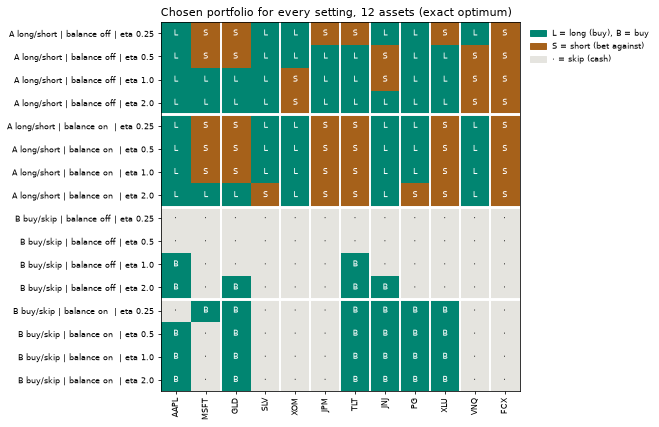

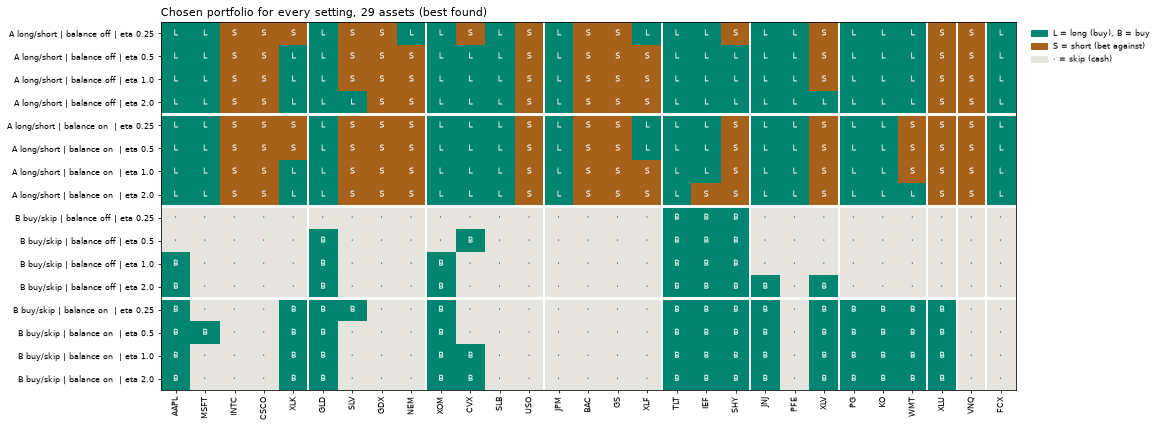

Text summary, n = 12, long_short: number of longs as eta rises [0.25, 0.5, 1.0, 2.0]: balance off [6, 7, 8, 9], balance on [6, 6, 6, 6]
Text summary, n = 12, buy_or_skip: number of buys as eta rises [0.25, 0.5, 1.0, 2.0]: balance off [0, 0, 2, 4], balance on [6, 6, 6, 6]
Text summary, n = 29, long_short: number of longs as eta rises [0.25, 0.5, 1.0, 2.0]: balance off [16, 17, 17, 19], balance on [15, 15, 15, 15]
Text summary, n = 29, buy_or_skip: number of buys as eta rises [0.25, 0.5, 1.0, 2.0]: balance off [3, 5, 6, 8], balance on [14, 14, 14, 14]


In [33]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

SHORT, SKIP, PLUS = 0, 1, 2
state_colors = ListedColormap([BROWN, "#e5e4df", TEAL])
for n in RUN_SIZES:
    tickers = setups3[n]["tickers"]
    order = [t for t in kaggle_data.TICKERS if t in tickers]
    idx = [tickers.index(t) for t in order]
    codes, letters, labels = [], [], []
    for r in results3[n]:
        spins = np.array(r["spins"])[idx]
        long_short = r["mode"] == ising.MODE_LONG_SHORT
        codes.append(np.where(spins > 0, PLUS, SHORT if long_short else SKIP))
        letters.append([("L" if long_short else "B") if v > 0 else ("S" if long_short else "·") for v in spins])
        labels.append(f"{'A long/short' if long_short else 'B buy/skip'} | balance {'on ' if r['balance'] else 'off'} | eta {r['eta']}")
    fig, ax = plt.subplots(figsize=(0.42 * n + 4.5, 6.2))
    ax.imshow(np.array(codes), cmap=state_colors, vmin=0, vmax=2, aspect="auto")
    for row, line in enumerate(letters):
        for col, letter in enumerate(line):
            ax.text(col, row, letter, ha="center", va="center", fontsize=8,
                    color="black" if codes[row][col] == SKIP else "white")
    ax.set_xticks(range(n), order, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    in_order = [kaggle_data.GROUP_OF[t] for t in order]
    for k in range(1, n):
        if in_order[k] != in_order[k - 1]:
            ax.axvline(k - 0.5, color="white", linewidth=2)
    for k in range(4, len(labels), 4):
        ax.axhline(k - 0.5, color="white", linewidth=3)
    kind = "exact optimum" if results3[n][0]["n_optimal"] is not None else "best found"
    ax.set_title(f"Chosen portfolio for every setting, {n} assets ({kind})", loc="left", fontsize=11)
    ax.legend(handles=[Patch(color=TEAL, label="L = long (buy), B = buy"), Patch(color=BROWN, label="S = short (bet against)"),
                       Patch(color="#e5e4df", label="· = skip (cash)")], loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()

for n in RUN_SIZES:
    for mode, plus in ((ising.MODE_LONG_SHORT, "longs"), (ising.MODE_BUY_OR_SKIP, "buys")):
        counts = {bal: [r["n_plus"] for r in results3[n] if r["mode"] == mode and r["balance"] == bal] for bal in (False, True)}
        print(f"Text summary, n = {n}, {mode}: number of {plus} as eta rises {list(ETA_GRID)}: balance off {counts[False]}, "
              f"balance on {counts[True]}")

**How to read these charts (which assets each setting picks)**
- **X axis:** the assets, grouped (white lines separate the groups).
- **Y axis:** the 16 settings: mode A (long/short) on top, mode B (buy or skip) below; inside each block the dial eta rises from 0.25 to 2, first with balance off, then on.
- **Squares:** teal **L** = long, teal **B** = buy, brown **S** = short (a bet against), grey **·** = skip (cash).
- **Conclusion:** the bonds are long or bought in almost every setting: the solver uses them as the safety net. Raising the dial moves more assets to the buy side (mode A, 12 assets: 6 → 9 longs). In mode B without the balance switch the safest answer is to hold very little: nothing at all for 12 assets at eta 0.25 and 0.5, because cash has no risk. The balance switch forces a fixed number of buys.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

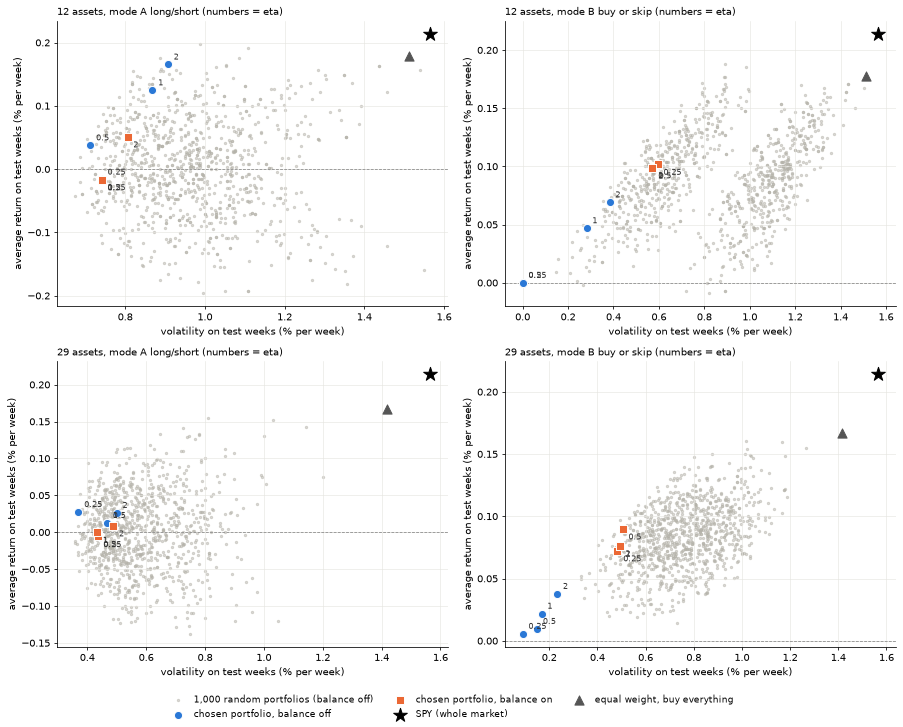

Text summary, n = 12, long_short: 8 of 8 settings were calmer than the typical random portfolio of the same kind; 4 of 8 earned more than the typical one (test weeks; no setting was chosen with these numbers)
Text summary, n = 12, buy_or_skip: 8 of 8 settings were calmer than the typical random portfolio of the same kind; 4 of 8 earned more than the typical one (test weeks; no setting was chosen with these numbers)
Text summary, n = 29, long_short: 8 of 8 settings were calmer than the typical random portfolio of the same kind; 5 of 8 earned more than the typical one (test weeks; no setting was chosen with these numbers)
Text summary, n = 29, buy_or_skip: 8 of 8 settings were calmer than the typical random portfolio of the same kind; 1 of 8 earned more than the typical one (test weeks; no setting was chosen with these numbers)


In [34]:
fig, axes = plt.subplots(len(RUN_SIZES), 2, figsize=(13, 5.2 * len(RUN_SIZES)), squeeze=False)
for row, n in enumerate(RUN_SIZES):
    setup = setups3[n]
    for ax, mode in zip(axes[row], ising.MODES):
        cloud_model = task3_report.build_model(setup, mode, RISK_RETURN_WEIGHT, False)
        cloud = classical_evaluation.random_portfolio_metrics(cloud_model, setup["test_assets"], task3_report.SETTINGS["random_portfolios"],
                                                              np.random.default_rng(task3_report.SETTINGS["portfolio_seed"]))
        ax.scatter(100 * cloud["volatility"], 100 * cloud["mean"], s=6, color="#b4b2a9", alpha=0.5, label="1,000 random portfolios (balance off)")
        for balance, color, marker in ((False, "#2a78d6", "o"), (True, "#eb6834", "s")):
            picks = [r for r in results3[n] if r["mode"] == mode and r["balance"] == balance]
            ax.scatter([100 * r["test"]["volatility"] for r in picks], [100 * r["test"]["mean"] for r in picks], s=70, color=color,
                       marker=marker, edgecolor="white", zorder=3, label=f"chosen portfolio, balance {'on' if balance else 'off'}")
            for r in picks:
                ax.annotate(f"{r['eta']:g}", (100 * r["test"]["volatility"], 100 * r["test"]["mean"]), xytext=(6, 5 if not balance else -11),
                            textcoords="offset points", fontsize=8, color="#333333")
        b, e = setup["benchmark_metrics"], setup["equal_weight_metrics"]
        ax.scatter(100 * b["volatility"], 100 * b["mean"], marker="*", s=220, color="black", zorder=3, label="SPY (whole market)")
        ax.scatter(100 * e["volatility"], 100 * e["mean"], marker="^", s=90, color="#555555", zorder=3, label="equal weight, buy everything")
        ax.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
        ax.set_xlabel("volatility on test weeks (% per week)")
        ax.set_ylabel("average return on test weeks (% per week)")
        ax.set_title(f"{n} assets, mode {'A long/short' if mode == ising.MODE_LONG_SHORT else 'B buy or skip'} (numbers = eta)", loc="left", fontsize=10)
        ax.grid(True, color="#e5e4df", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

for n in RUN_SIZES:
    for mode in ising.MODES:
        picks = [r for r in results3[n] if r["mode"] == mode]
        below = sum(r["test_percentile_volatility"] < 50 for r in picks)
        above = sum(r["test_percentile_mean"] > 50 for r in picks)
        print(f"Text summary, n = {n}, {mode}: {below} of {len(picks)} settings were calmer than the typical random portfolio of the "
              f"same kind; {above} of {len(picks)} earned more than the typical one (test weeks; no setting was chosen with these numbers)")

**How to read this chart (did it work on the hidden test weeks?)**
- **X axis:** how much the portfolio moved up and down on the 180 test weeks (weekly volatility, %). Left = calmer.
- **Y axis:** its average return per week on the test weeks (%). Higher = earned more.
- **Marks:** grey dots = 1,000 random portfolios of the same mode; blue circles = our portfolios with balance off, orange squares = balance on; the number next to a mark is the dial eta (marks overlap when two settings pick the same portfolio); black star = the whole market (SPY); triangle = buying every asset equally.
- **Conclusion:** all 32 chosen portfolios sit on the left: each was calmer than the typical random portfolio of its kind, so the risk part of the score held up on unseen weeks. Returns are mixed: 14 of 32 earned more than a typical random portfolio, and **none earned more than simply holding the market**, which rose strongly in 2014–2017. The method lowered risk; it did not raise profit. No setting was chosen using these numbers.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

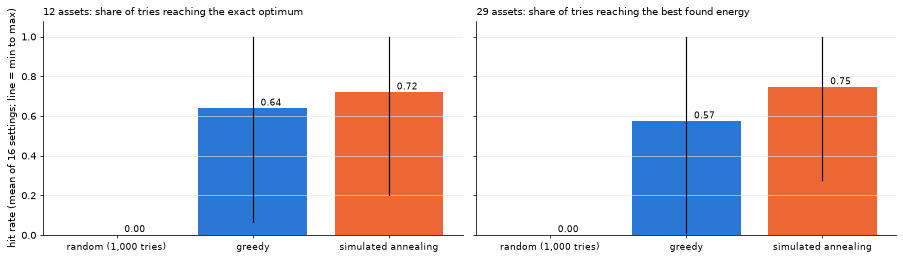

Text summary, n = 12: mean hit rate random 0.0006, greedy 0.64, simulated annealing 0.72
Text summary, n = 29: mean hit rate random 0.0000, greedy 0.57, simulated annealing 0.75


In [35]:
solver_names = {"random": "random (1,000 tries)", "greedy": "greedy", "annealing": "simulated annealing"}
fig, axes = plt.subplots(1, len(RUN_SIZES), figsize=(6.5 * len(RUN_SIZES), 3.8), squeeze=False, sharey=True)
for ax, n in zip(axes[0], RUN_SIZES):
    rates = {name: [r["solvers"][name]["hit_rate_mean"] for r in results3[n]] for name in solver_names}
    means = [np.mean(rates[name]) for name in solver_names]
    ax.bar(range(3), means, color=["#b4b2a9", "#2a78d6", "#eb6834"])
    for k, name in enumerate(solver_names):
        ax.plot([k, k], [min(rates[name]), max(rates[name])], color="black", linewidth=1.2)
        ax.annotate(f"{means[k]:.2f}", (k, means[k]), xytext=(8, 3), textcoords="offset points", fontsize=9)
    ax.set_xticks(range(3), list(solver_names.values()), fontsize=9)
    ax.set_ylim(0, 1.08)
    target = "the exact optimum" if results3[n][0]["n_optimal"] is not None else "the best found energy"
    ax.set_title(f"{n} assets: share of tries reaching {target}", loc="left", fontsize=10)
    ax.grid(True, axis="y", color="#e5e4df", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0][0].set_ylabel("hit rate (mean of 16 settings; line = min to max)")
fig.tight_layout()
plt.show()

for n in RUN_SIZES:
    means = {name: np.mean([r["solvers"][name]["hit_rate_mean"] for r in results3[n]]) for name in solver_names}
    print(f"Text summary, n = {n}: mean hit rate random {means['random']:.4f}, greedy {means['greedy']:.2f}, simulated annealing {means['annealing']:.2f}")

**How to read this chart (how good are the classical solvers?)**
- **X axis:** the three classical solvers.
- **Y axis:** hit rate = the share of tries that reach the reference answer (the exact optimum for 12 assets, the best found answer for 29 assets). The bar is the average over the 16 settings; the black line runs from the worst to the best setting.
- **Conclusion:** random guessing almost never finds the best portfolio (about 1 try in 1,700 for 12 assets, never for 29). Greedy and simulated annealing reach it in most tries. These bars are what the quantum result must be compared with in the next task.

*Numbers are from the run of 10 Oct 2026; the printed summary above recomputes them.*

### 3.H Task 3 report (also runs all unit tests)

Same output as `python -m stocks.task3_report`; it re-runs the grid, saves `results/stocks_task3_classical.json` and runs the whole test suite.

In [36]:
task3_exit = task3_report.main(train_fraction=TRAIN_FRACTION, sizes=tuple(RUN_SIZES), keep_fraction=KEEP_FRACTION, target_buys=TARGET_BUYS)

[TASK 3] Ising encoding, exact and classical baselines (classical only)
- Branch stocks, HEAD before this commit: 38882d7 docs(stocks): how-to-read notes (axes and conclusion) under every chart
- Split: train 418 weeks (2006-06-02 to 2014-05-30), test 180 weeks (2014-06-06 to 2017-11-10); nothing tuned on test
- Grid per size: modes ['long_short', 'buy_or_skip'] x eta [0.25, 0.5, 1.0, 2.0] x balance [off, on] = 16 configurations; seeds [2026, 2027, 2028]
- n=12: keep fraction 1.0, kept 66 of 66 pairs by |rho|, kept negative links 14 of 14, isolated: none
    exact enumeration of 4096 states per configuration; tied optima per configuration: [1]; penalty check (no unbalanced state beats the best balanced): 8/8 pass, smallest margin 0.2679
    held-out context: SPY mean +0.214%/week, vol 1.57%, worst -5.9%; equal-weight long-only mean +0.178%, vol 1.51%, worst -4.4%
    long_short  eta 0.25 bal off | E_model +0.02606 dense +0.02606 |    6L/6S | hit rnd/grd/SA 0.000/0.07/0.20 | test mean -

- Tests (python -m unittest discover -s tests -t .): 94 passed, 0 failed, 0 skipped
RESULT: PASS
